# Chapter 3 — Statistical Learning Theory

*Why does a model that fits the training data also work on new data? When can we trust it, and how much?*

## 3.1 Learning objectives

In Chapter 1 we trained models and measured them on data they had not seen. In Chapter 2 we learned that an average over a sample is an estimate of an expectation. This chapter puts the two ideas together. It answers a question that every method in the rest of the book silently relies on: **why should a function that has a small error on the training set have a small error on future data?** The answer is not "always": we will see exactly when it holds, how fast it improves with the number of examples, and what it depends on.

After working through this chapter you will be able to:

1. define the **data distribution**, the **expected risk** and the **empirical risk**, and explain why the whole of machine learning is about the gap between them;
2. derive the **Bayes-optimal predictor** for the squared loss and for the 0–1 loss, and explain why a part of the error can never be removed;
3. write **empirical risk minimization** (ERM) and split the excess risk into an **approximation error** and an **estimation error**;
4. explain, with a short proof and with experiments, why the **training error is optimistic**, and quantify the optimism when many candidate models are compared;
5. state **Markov's, Chebyshev's and Hoeffding's inequalities**, and derive Hoeffding's inequality;
6. prove a **generalization bound for a finite hypothesis class** with the union bound, and turn it into a **sample-complexity** formula;
7. define **shattering, the growth function and the VC dimension**, compute them for simple classes, and state the VC generalization bound;
8. define the **Rademacher complexity**, derive its bound for norm-bounded linear classifiers, and explain why *controlling the norm* (regularization, large margins) controls generalization even when the dimension is larger than the number of examples;
9. state the **No Free Lunch** theorem and explain what an **inductive bias** is;
10. use Hoeffding's inequality to **size a test set**, and judge honestly how loose the bounds of the theory are on a real data set.

**Prerequisites.** Chapters 1 and 2, in particular Sections 1.5 (loss and risk) and 2.6 (expectation, variance, the law of large numbers). Calculus and the matrix notation of the previous chapters. No measure theory: random variables are treated as in Chapter 2.

**How to read this chapter.** It is the most mathematical chapter of Part I, and it is built so that you can read it at two depths. Each section has the same rhythm: an **idea** in words, a precise **statement**, a **proof** (marked, and safe to skip at a first reading), and an **experiment** that makes the statement concrete. The experiments carry the message; the proofs explain why the message is true. If you skip every proof you will still be able to follow the book. If you read them all, you will have seen the three classical ways of measuring the capacity of a model: its *size* (Section 3.6), its *shattering power* (Section 3.7) and its *ability to fit noise* (Section 3.8).

:::{admonition} A word about the data in this chapter
:class: note
Theory talks about a distribution $\mathcal{D}$ that is *unknown* in practice. To check a statement about $\mathcal{D}$ numerically we need a world where we **do** know it. In Sections 3.2, 3.3 and 3.4 we therefore use a small simulated world, and from Section 3.6 on we also use a *real* data set (Breast Cancer, seen in Chapter 1), treated as the population from which we draw samples. Whenever a number comes from a simulation, the text says so.
:::

### Setting up this notebook

As in the previous chapters, the next two cells print the versions of the libraries and define the plotting style and the random seed.

In [1]:
import platform
from importlib.metadata import version

print("Python", platform.python_version())
for pkg in ["numpy", "scipy", "pandas", "matplotlib", "scikit-learn"]:
    print(f"{pkg:<14}{version(pkg)}")

Python 3.15.2
numpy         2.5.5
scipy         1.18.1
pandas        3.1.1
matplotlib    3.11.2
scikit-learn  1.9.1


In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.exceptions import ConvergenceWarning

# The experiments below fit hundreds of models, some on tiny samples: silence the convergence messages.
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42  # fixed seed: random operations give the same result every time

# Plotting style used throughout the book (Okabe-Ito colors, safe for color-vision deficiencies).
BLUE, ORANGE, GREEN = "#0072B2", "#E69F00", "#009E73"
VERMILION, SKY, PURPLE = "#D55E00", "#56B4E9", "#CC79A7"
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (6.4, 4.0),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

## 3.2 The setting: distribution, loss, and risk

### 3.2.1 The data are random draws from an unknown distribution

Everything in this chapter rests on one modeling assumption. There is a **joint distribution** $\mathcal{D}$ over pairs $(\mathbf{x}, y)$ of an input and a label, which we cannot see, and the training set
$$
S = \{(\mathbf{x}_1, y_1), \dots, (\mathbf{x}_n, y_n)\}
$$
consists of $n$ pairs **drawn independently from $\mathcal{D}$** ("i.i.d.": independent and identically distributed). A future example, the one we care about, is one more independent draw from the same $\mathcal{D}$. A **prediction function** is a map $f$ from inputs to predictions $\hat y = f(\mathbf{x})$, and a **loss** $\ell(y, \hat y) \ge 0$ scores a single prediction (Section 1.5). The two quantities that matter are

$$
R(f) = \mathbb{E}_{(\mathbf{x}, y) \sim \mathcal{D}}\big[\ell\big(y, f(\mathbf{x})\big)\big]
\qquad\text{and}\qquad
\hat{R}_S(f) = \frac{1}{n}\sum_{i=1}^{n} \ell\big(y_i, f(\mathbf{x}_i)\big).
$$

$R(f)$ is the **expected risk** (also called the true risk or the generalization error): the average loss on a *new* example. $\hat{R}_S(f)$ is the **empirical risk**: the average loss on the training set, which we can compute. The first is what we want; the second is what we have. Section 2.6 told us that $\hat{R}_S(f)$ is a sample mean of the random variable $\ell(y, f(\mathbf{x}))$ and that $R(f)$ is its expectation, so the whole chapter is about how far a sample mean can be from the mean *when the function $f$ itself has been chosen by looking at the sample*.

:::{admonition} Pitfall — the i.i.d. assumption is a modeling choice, not a fact
:class: warning
The theory below applies when the training examples are independent draws and the future examples come from the same distribution. It fails, quietly, when the data are a time series (today resembles yesterday), when several rows come from the same patient or the same house (they are not independent), or when the model will be used on a different population from the one it was trained on. These situations do not make learning impossible, but the guarantees of this chapter no longer apply as stated, and the *splitting strategy* has to change (Chapter 5). Most "my model worked in the lab and failed in production" stories are violations of this assumption.
:::

### 3.2.2 The best possible predictor: the Bayes predictor

If we knew $\mathcal{D}$, which function would we choose? Take the infimum of the risk over **all** functions,
$$
R^\ast = \inf_{f} R(f),
$$
and call a function that achieves it a **Bayes-optimal predictor** $f^\ast$. It is a benchmark that no method, however clever and however much data it has, can beat. It can be found one input at a time, because the risk is an average over $\mathbf{x}$ of a *conditional* risk:
$$
R(f) = \mathbb{E}_{\mathbf{x}}\Big[\,\underbrace{\mathbb{E}\big[\ell(y, f(\mathbf{x})) \mid \mathbf{x}\big]}_{\text{conditional risk at } \mathbf{x}}\,\Big].
$$
This is the law of total expectation of Section 2.6. To make $R(f)$ small it is enough, and necessary, to make the conditional risk small *at every $\mathbf{x}$*, which means choosing for each $\mathbf{x}$ the best single prediction $a = f(\mathbf{x})$ given what $\mathbf{x}$ tells us about $y$. Let us do it for the two most common losses.

**Squared loss (regression).** Write $\eta(\mathbf{x}) = \mathbb{E}[y \mid \mathbf{x}]$, the conditional mean. For any number $a$,
$$
\mathbb{E}\big[(y - a)^2 \mid \mathbf{x}\big]
= \mathbb{E}\big[(y - \eta(\mathbf{x}))^2 \mid \mathbf{x}\big] + (\eta(\mathbf{x}) - a)^2
= \operatorname{Var}(y \mid \mathbf{x}) + (\eta(\mathbf{x}) - a)^2 .
$$
(Add and subtract $\eta(\mathbf{x})$ inside the square; the cross term has zero expectation because $\mathbb{E}[y - \eta(\mathbf{x}) \mid \mathbf{x}] = 0$.) The second term is smallest, and equal to zero, for $a = \eta(\mathbf{x})$. Hence
$$
\boxed{\,f^\ast(\mathbf{x}) = \mathbb{E}[y \mid \mathbf{x}], \qquad R^\ast = \mathbb{E}\big[\operatorname{Var}(y \mid \mathbf{x})\big]\,}
\qquad\text{and}\qquad
R(f) - R^\ast = \mathbb{E}\big[(f(\mathbf{x}) - \eta(\mathbf{x}))^2\big].
$$
The best regression function is the **conditional mean**, and the floor $R^\ast$ is the average *noise* around it: the part of $y$ that the input does not determine. For a constant predictor (no input) this is the result of Section 1.5, the sample mean; for the Bayes predictor the same idea is applied at every $\mathbf{x}$.

**0–1 loss (binary classification).** Let $y \in \{0, 1\}$ and $\eta(\mathbf{x}) = \mathbb{P}(y = 1 \mid \mathbf{x})$. Predicting $a \in \{0, 1\}$ is wrong with probability $\mathbb{P}(y \neq a \mid \mathbf{x})$, which is $1 - \eta(\mathbf{x})$ if $a = 1$ and $\eta(\mathbf{x})$ if $a = 0$. The smaller of the two is obtained by predicting the more probable class:
$$
\boxed{\,f^\ast(\mathbf{x}) = \mathbb{I}\big[\eta(\mathbf{x}) > \tfrac12\big], \qquad R^\ast = \mathbb{E}\big[\min\{\eta(\mathbf{x}),\, 1 - \eta(\mathbf{x})\}\big]\,}
$$
This is the **Bayes classifier**. By Bayes' rule of Section 2.6 it can be written in terms of the class-conditional densities $p_k(\mathbf{x})$ and the priors $\pi_k = \mathbb{P}(y = k)$: predict class 1 when $\pi_1 p_1(\mathbf{x}) > \pi_0 p_0(\mathbf{x})$. The floor $R^\ast$ is the average, over $\mathbf{x}$, of the probability of the *less likely* class: it is zero only if the label is a deterministic function of the input.

(For the absolute loss $\lvert y - a \rvert$ the same argument gives the conditional **median** instead of the mean; see Exercise 3.2.)

:::{admonition} Key idea
:class: tip
**Noise sets a floor.** Even a perfect learner with infinite data has an error $R^\ast > 0$ whenever the label is not a function of the features alone. Two patients with identical measurements can have different outcomes; two e-mails with identical words can be spam and not spam. A model with 85% accuracy on a problem whose Bayes accuracy is 86% is *excellent*; the same model on a problem whose Bayes accuracy is 99% is poor. On real data $R^\ast$ is unknown, which is why a single accuracy number can never tell whether there is room for improvement.
:::

### Worked example 3.1 — the Bayes classifier of two Gaussians

Let the input be a single number $x$ and the two classes be equally likely, with $x \mid y = 0 \sim \mathcal{N}(0, 1)$ and $x \mid y = 1 \sim \mathcal{N}(3, 1)$. With equal priors the Bayes classifier predicts the class with the larger density; the two Gaussians have the same variance, so their densities are equal at the midpoint, and
$$
f^\ast(x) = \mathbb{I}[x > 1.5].
$$
An error occurs when a class-0 point falls to the right of $1.5$ or a class-1 point falls to the left of it. By symmetry both events have the same probability, $\mathbb{P}(\mathcal{N}(0, 1) > 1.5) = \Phi(-1.5)$, where $\Phi$ is the cumulative distribution function of the standard Gaussian. Hence
$$
R^\ast = \tfrac12\,\Phi(-1.5) + \tfrac12\,\Phi(-1.5) = \Phi(-1.5) \approx 0.0668 .
$$
Even in this friendly problem, 6.7% of the examples are misclassified by the best possible rule, because the two bells overlap. Let us check the number with a simulation.

In [3]:
rng = np.random.default_rng(SEED)
n_mc = 1_000_000
y = rng.integers(0, 2, size=n_mc)                       # equally likely classes
x = rng.normal(loc=3.0 * y, scale=1.0)                  # class 0: N(0,1), class 1: N(3,1)

bayes_pred = (x > 1.5).astype(int)
print(f"exact Bayes risk  Phi(-1.5)      : {stats.norm.cdf(-1.5):.4f}")
print(f"Monte Carlo risk of the rule x>1.5: {np.mean(bayes_pred != y):.4f}")
for t in (1.0, 1.25, 1.75, 2.0):                        # any other threshold does worse
    print(f"risk of the rule x>{t:<4}          : {np.mean((x > t) != y):.4f}")

exact Bayes risk  Phi(-1.5)      : 0.0668
Monte Carlo risk of the rule x>1.5: 0.0668
risk of the rule x>1.0           : 0.0908
risk of the rule x>1.25          : 0.0730
risk of the rule x>1.75          : 0.0726
risk of the rule x>2.0           : 0.0903


### 3.2.3 A world where we know $\mathcal{D}$

For the experiments of this chapter we need a problem in the plane where the Bayes classifier is known, but where a *linear* classifier cannot reach it. Class 0 is a round Gaussian cloud centered at the origin. Class 1 is a narrow vertical band: a Gaussian with a small variance in $x_1$ and a large variance in $x_2$, centered at $(0.6, 0)$. The classes are equally likely. We will call it **the simulated world**.

The log-ratio of two Gaussian densities is a quadratic function of $\mathbf{x}$, so the boundary of the Bayes classifier is a **conic** (here two curves), not a line. That is deliberate: it will let us see, in numbers, the difference between the best that *any* classifier can do and the best that a *linear* classifier can do.

In [4]:
from scipy.stats import multivariate_normal

# The simulated world: two classes in the plane, equally likely.
MU = [np.array([0.0, 0.0]), np.array([0.6, 0.0])]
COV = [np.diag([1.0, 1.0]), np.diag([0.1, 6.0])]
dens = [multivariate_normal(MU[k], COV[k]) for k in (0, 1)]


def sample_world(n, rng):
    """Draw n i.i.d. pairs (x, y) from the distribution D of the simulated world."""
    y = rng.integers(0, 2, size=n)
    X = np.empty((n, 2))
    for k in (0, 1):
        idx = y == k
        X[idx] = rng.multivariate_normal(MU[k], COV[k], size=idx.sum())
    return X, y


def bayes_predict(X):
    """The Bayes classifier: predict the class with the larger density (the priors are equal)."""
    return (dens[1].logpdf(X) > dens[0].logpdf(X)).astype(int)


rng = np.random.default_rng(SEED)
X_big, y_big = sample_world(2_000_000, rng)
errors = bayes_predict(X_big) != y_big
R_BAYES = errors.mean()
print(f"Bayes risk R* of the simulated world: {R_BAYES:.4f}   (Monte Carlo error +/- {errors.std() / np.sqrt(len(errors)):.4f})")
print(f"error on class 0: {errors[y_big == 0].mean():.4f} | error on class 1: {errors[y_big == 1].mean():.4f}")

Bayes risk R* of the simulated world: 0.1891   (Monte Carlo error +/- 0.0003)
error on class 0: 0.2653 | error on class 1: 0.1128


About 19% of the points are misclassified by the best possible rule: the Bayes risk of this world is $R^\ast \approx 0.189$. The next cell finds the best **linear** classifier of this world by brute force (all directions, all thresholds, on 300,000 points) and measures its risk on points it has not seen. The search is cheap because a linear classifier in the plane is a direction and a threshold.

In [5]:
def best_linear_classifier(X, y, n_angles=360):
    """Exhaustive search of the linear classifier with the smallest 0-1 error: 'predict 1 if w.x > t'."""
    n, best = len(y), (1.0, None, None)
    for theta in np.linspace(0, np.pi, n_angles, endpoint=False):
        w = np.array([np.cos(theta), np.sin(theta)])
        order = np.argsort(X @ w)
        ys, proj = y[order], (X @ w)[order]
        below1, below0 = np.cumsum(ys == 1), np.cumsum(ys == 0)
        err_pred1_above = below1 + (below0[-1] - below0)       # errors if we predict 1 above the cut after position i
        for sign, errs in ((1.0, err_pred1_above), (-1.0, n - err_pred1_above)):
            i = errs.argmin()
            if errs[i] / n < best[0]:
                cut = (proj[i] + proj[min(i + 1, n - 1)]) / 2
                best = (errs[i] / n, sign * w, sign * cut)
    return best


_, w_lin, t_lin = best_linear_classifier(X_big[:300_000], y_big[:300_000])
fresh = slice(300_000, None)                                      # points the search has never seen
R_LINEAR = np.mean((X_big[fresh] @ w_lin > t_lin).astype(int) != y_big[fresh])
print(f"best linear classifier: direction {np.round(w_lin, 3)}, threshold {t_lin:.3f}")
print(f"risk of the best linear classifier: {R_LINEAR:.4f}   (Bayes risk: {R_BAYES:.4f})")

best linear classifier: direction [1. 0.], threshold 0.117
risk of the best linear classifier: 0.2587   (Bayes risk: 0.1891)


The best linear classifier is a vertical line, with a risk of about 0.259: **seven percentage points worse than the Bayes classifier**, and no amount of data will close that gap, because the gap is a property of the *class of functions*, not of the sample. Figure 3.1 shows the two boundaries.

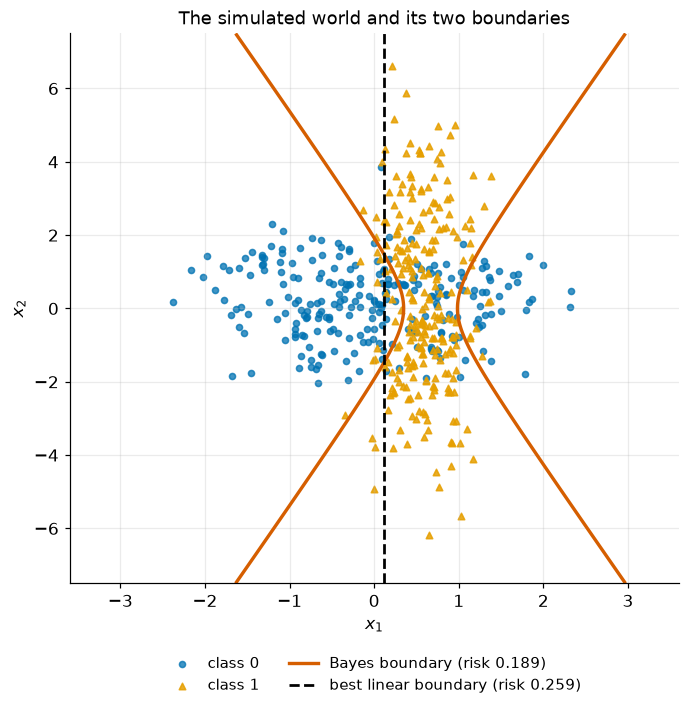

In [6]:
# Figure 3.1 — the simulated world: data, Bayes boundary, and the best linear boundary
def figure_3_1():
    rng = np.random.default_rng(SEED + 7)
    X, y = sample_world(500, rng)

    gx, gy = np.meshgrid(np.linspace(-3.6, 3.6, 400), np.linspace(-7.5, 7.5, 600))
    grid = np.column_stack([gx.ravel(), gy.ravel()])
    log_ratio = (dens[1].logpdf(grid) - dens[0].logpdf(grid)).reshape(gx.shape)

    fig, ax = plt.subplots(figsize=(6.4, 6.6))
    ax.scatter(*X[y == 0].T, s=16, color=BLUE, marker="o", alpha=0.75, label="class 0")
    ax.scatter(*X[y == 1].T, s=18, color=ORANGE, marker="^", alpha=0.85, label="class 1")
    ax.contour(gx, gy, log_ratio, levels=[0], colors=[VERMILION], linewidths=2.2)
    ax.plot([], [], color=VERMILION, linewidth=2.2, label=f"Bayes boundary (risk {R_BAYES:.3f})")
    ax.axvline(t_lin, color="black", linestyle="--", linewidth=1.8, label=f"best linear boundary (risk {R_LINEAR:.3f})")
    ax.set(xlabel="$x_1$", ylabel="$x_2$", xlim=(-3.6, 3.6), ylim=(-7.5, 7.5),
           title="The simulated world and its two boundaries")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=2, frameon=False, fontsize=9.5)
    fig.tight_layout()
    plt.show()


figure_3_1()

Class 0 (circles) is the round cloud. Class 1 (triangles) is the tall thin band that crosses it. The Bayes boundary (solid) has two branches, and class 1 is predicted *between* them: a region that is narrow near the origin and widens for large $\lvert x_2 \rvert$, where the broad class-1 density wins over the round class-0 density. No single straight line can do that. The best line (dashed) simply cuts the cloud vertically near $x_1 \approx 0.1$.

:::{admonition} Try it
:class: note
Change the covariance of class 1 in the cell that defines `COV` (for instance to `np.diag([1.0, 1.0])`) and re-run the notebook from that point on. With equal covariances the Bayes boundary becomes a straight line, the best linear classifier *is* the Bayes classifier, and the 7-point gap disappears.
:::

## 3.3 Empirical risk minimization and the two sources of error

We cannot minimize $R(f)$, because we do not know $\mathcal{D}$. We can minimize $\hat{R}_S(f)$, which we can compute, and we cannot afford to search over *all* functions: with a finite sample, some function always matches the training labels exactly (for instance, a table of the training set, which says nothing about new inputs). So we restrict the search to a **hypothesis class** $\mathcal{H}$, a set of functions chosen in advance: the lines in the plane, the polynomials of degree at most 3, the neural networks with a given architecture. **Empirical risk minimization** returns a function of $\mathcal{H}$ with the smallest empirical risk:
$$
\hat f_S \in \operatorname*{argmin}_{f \in \mathcal{H}} \hat{R}_S(f).
$$
This is the principle announced in Section 1.5. Two remarks keep the story honest. First, $\hat f_S$ **depends on the random sample**, so it is itself random: a different training set gives a different function. Second, for the 0–1 loss the minimization is computationally hard for many classes (minimizing the number of mistakes of a linear classifier is NP-hard in general), so practical methods minimize a smooth substitute such as the logistic loss (Chapter 6) or the hinge loss (Chapter 8). Here we think of ideal ERM, and in the experiments we use logistic regression as a practical stand-in.

### 3.3.1 The decomposition of the excess risk

Let $f_{\mathcal{H}}$ be the **best function in the class**, $f_{\mathcal{H}} \in \operatorname{argmin}_{f \in \mathcal{H}} R(f)$: the function we would pick if we knew $\mathcal{D}$ but were limited to $\mathcal{H}$. Adding and subtracting $R(f_{\mathcal{H}})$ splits the excess risk of the learned function over the unbeatable Bayes risk into two parts:

$$
\underbrace{R(\hat f_S) - R^\ast}_{\text{excess risk}}
= \underbrace{\big[R(\hat f_S) - R(f_{\mathcal{H}})\big]}_{\text{estimation error}}
+ \underbrace{\big[R(f_{\mathcal{H}}) - R^\ast\big]}_{\text{approximation error}} .
$$

- The **approximation error** measures how well the *class* can do even with perfect knowledge of $\mathcal{D}$. It does not depend on $n$ or on the sample; it shrinks only if we enlarge $\mathcal{H}$. In the simulated world, the approximation error of the lines is $0.259 - 0.189 = 0.070$.
- The **estimation error** measures what we lose by choosing the function from a finite random sample instead of from $\mathcal{D}$. It is random, it shrinks as $n$ grows, and it grows with the richness of $\mathcal{H}$ (more candidates, more ways to be fooled by the sample, as Section 3.4 shows).

Figure 3.2 sketches the picture: the Bayes predictor lives outside the class, the best function in the class is the closest we can get, and ERM lands somewhere around it.

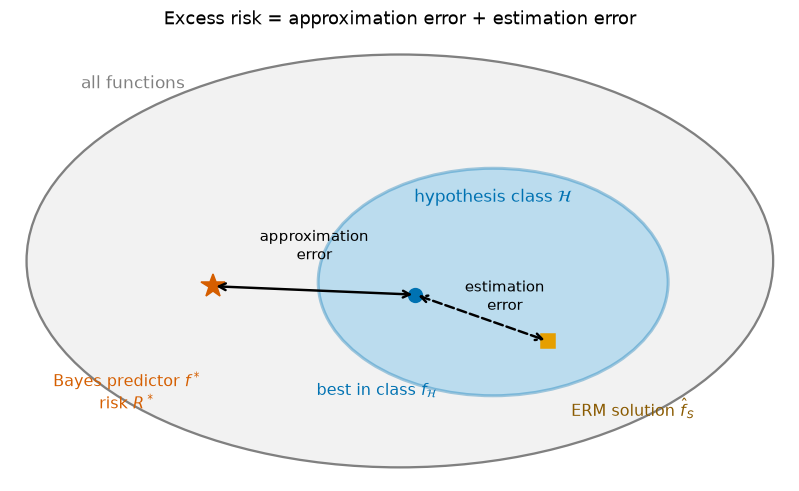

In [7]:
# Figure 3.2 — a schematic of the two sources of error (not to scale)
def figure_3_2():
    from matplotlib.patches import Ellipse

    fig, ax = plt.subplots(figsize=(7.4, 4.6))
    ax.add_patch(Ellipse((5.0, 2.6), 9.6, 4.9, facecolor="#f2f2f2", edgecolor="gray", linewidth=1.5))
    ax.add_patch(Ellipse((6.2, 2.35), 4.5, 2.7, facecolor=SKY, alpha=0.35, edgecolor=BLUE, linewidth=2))
    ax.text(0.9, 4.65, "all functions", fontsize=11, color="gray")
    ax.text(6.2, 3.3, r"hypothesis class $\mathcal{H}$", fontsize=11, color=BLUE, ha="center")

    p_bayes, p_best, p_erm = (2.6, 2.3), (5.2, 2.2), (6.9, 1.65)
    ax.plot(*p_bayes, marker="*", markersize=16, color=VERMILION)
    ax.plot(*p_best, marker="o", markersize=9, color=BLUE)
    ax.plot(*p_erm, marker="s", markersize=9, color=ORANGE)
    ax.annotate(r"Bayes predictor $f^*$" "\n" r"risk $R^*$", p_bayes, xytext=(1.5, 0.85), fontsize=10.5, ha="center", color=VERMILION)
    ax.annotate(r"best in class $f_{\mathcal{H}}$", p_best, xytext=(4.7, 1.0), fontsize=10.5, ha="center", color=BLUE)
    ax.annotate(r"ERM solution $\hat f_S$", p_erm, xytext=(8.0, 0.75), fontsize=10.5, ha="center", color="#8a5a00")
    ax.annotate("", p_best, p_bayes, arrowprops={"arrowstyle": "<->", "color": "black", "linewidth": 1.6})
    ax.annotate("", p_erm, p_best, arrowprops={"arrowstyle": "<->", "color": "black", "linewidth": 1.6, "linestyle": "--"})
    ax.text(3.9, 2.62, "approximation\nerror", ha="center", fontsize=10)
    ax.text(6.35, 2.02, "estimation\nerror", ha="center", fontsize=10)
    ax.set(xlim=(0, 10), ylim=(0, 5.3))
    ax.axis("off")
    ax.set_title("Excess risk = approximation error + estimation error")
    fig.tight_layout()
    plt.show()


figure_3_2()

### 3.3.2 The trade-off, measured

Enlarging $\mathcal{H}$ reduces the approximation error and increases the estimation error. To see both effects we use classes of increasing richness: **logistic regression on the polynomial features of degree $m$** of $(x_1, x_2)$, for $m = 1$ (lines), $m = 2$ (conics, which contain the Bayes classifier of this world, so the approximation error is zero), up to $m = 8$ (44 features). We draw many training sets of size $n$ from the simulated world, fit each class, and measure the risk of the result on a fresh test set of 100,000 points, which gives the *true* risk up to a Monte Carlo error of about 0.001. We use a very weak regularization (`C=1000`) so that logistic regression behaves like unregularized ERM; the role of regularization is the subject of Chapter 6.

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler


def make_poly_model(degree):
    return make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(),
                         LogisticRegression(C=1000.0, max_iter=5000))


rng = np.random.default_rng(SEED + 1)
X_test, y_test = sample_world(100_000, rng)          # one big test set: its error is the true risk, up to ~0.001


def risks(degree, n, reps):
    """Mean training error and mean true risk of the fitted model, over `reps` training sets of size n."""
    train_err, test_err = [], []
    for _ in range(reps):
        X, y = sample_world(n, rng)
        model = make_poly_model(degree).fit(X, y)
        train_err.append(np.mean(model.predict(X) != y))
        test_err.append(np.mean(model.predict(X_test) != y_test))
    return np.mean(train_err), np.mean(test_err)


degrees = [1, 2, 3, 4, 6, 8]
sizes_left = [30, 300, 3000]
by_degree = {n: [risks(m, n, reps=60) for m in degrees] for n in sizes_left}

table = pd.DataFrame({f"n={n}, test risk": [r[1] for r in by_degree[n]] for n in sizes_left}, index=degrees)
table["n=30, TRAINING error"] = [r[0] for r in by_degree[30]]
table.index.name = "degree m"
print(f"Bayes risk R* = {R_BAYES:.3f}; best linear classifier = {R_LINEAR:.3f}")
table.round(3)

Bayes risk R* = 0.189; best linear classifier = 0.259


,"n=30, test risk","n=300, test risk","n=3000, test risk","n=30, TRAINING error"
degree m,,,,
1,0.342,0.296,0.284,0.266
2,0.253,0.193,0.188,0.128
3,0.270,0.197,0.188,0.078
4,0.287,0.201,0.189,0.069
6,0.289,0.205,0.189,0.055
8,0.296,0.207,0.189,0.049


Read the table column by column.

- **$n = 30$ (few data).** The test risk is U-shaped: it falls from 0.34 (lines, large approximation error) to its minimum of 0.25 at degree 2, and then **rises** again to 0.30 at degree 8, because a class with 44 features has too much freedom for 30 points: the estimation error dominates. The **training error** (last column) does the opposite: it decreases all the way down to 0.05. *The training error always prefers the richer class, and is therefore useless for choosing it.*
- **$n = 300$.** The best class is still degree 2, and the penalty for the richer classes has shrunk (0.207 at degree 8): more data, smaller estimation error.
- **$n = 3000$.** Every class with degree $\ge 2$ is within noise of the Bayes risk (0.189): the estimation error has become negligible, and what separates the classes is only the approximation error, which is zero for all of them. The lines, instead, stay at 0.28 (the logistic loss is a proxy for the 0–1 loss, so it does a little worse than the best line, 0.259).

The second experiment shows the effect of $n$ for three classes, in a **learning curve**.

In [9]:
sizes_curve = [10, 20, 40, 80, 160, 320, 640, 1280, 2560]
curve_degrees = [1, 2, 8]
curves = {m: [risks(m, n, reps=100 if n <= 320 else 40) for n in sizes_curve] for m in curve_degrees}
pd.DataFrame({f"degree {m}": [r[1] for r in curves[m]] for m in curve_degrees}, index=pd.Index(sizes_curve, name="n")).round(3)

,degree 1,degree 2,degree 8
n,,,
10,0.381,0.352,0.352
20,0.360,0.271,0.323
40,0.348,0.231,0.274
80,0.326,0.210,0.247
160,0.312,0.198,0.224
320,0.301,0.192,0.205
640,0.285,0.190,0.197
1280,0.291,0.188,0.191
2560,0.283,0.188,0.190


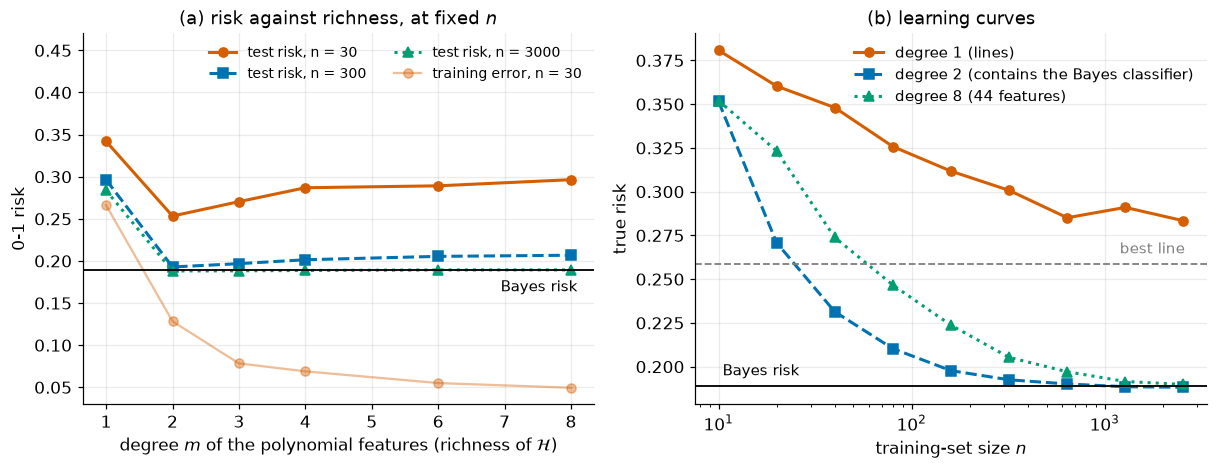

In [10]:
# Figure 3.3 — approximation vs estimation error, measured in the simulated world
def figure_3_3():
    fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.4))

    ax = axes[0]
    styles = {30: (VERMILION, "o", "-"), 300: (BLUE, "s", "--"), 3000: (GREEN, "^", ":")}
    for n in sizes_left:
        color, marker, ls = styles[n]
        ax.plot(degrees, [r[1] for r in by_degree[n]], marker=marker, linestyle=ls, color=color, linewidth=2, label=f"test risk, n = {n}")
    ax.plot(degrees, [r[0] for r in by_degree[30]], marker="o", linestyle="-", color=VERMILION, alpha=0.4, label="training error, n = 30")
    ax.axhline(R_BAYES, color="black", linewidth=1.2)
    ax.text(8.1, R_BAYES - 0.012, "Bayes risk", ha="right", va="top", fontsize=9.5)
    ax.set(xlabel="degree $m$ of the polynomial features (richness of $\\mathcal{H}$)", ylabel="0-1 risk",
           title="(a) risk against richness, at fixed $n$")
    ax.set_ylim(0.03, 0.47)
    ax.legend(frameon=False, fontsize=9, ncol=2, loc="upper right")

    ax = axes[1]
    styles = {1: (VERMILION, "o", "-"), 2: (BLUE, "s", "--"), 8: (GREEN, "^", ":")}
    names = {1: "degree 1 (lines)", 2: "degree 2 (contains the Bayes classifier)", 8: "degree 8 (44 features)"}
    for m in curve_degrees:
        color, marker, ls = styles[m]
        ax.plot(sizes_curve, [r[1] for r in curves[m]], marker=marker, linestyle=ls, color=color, linewidth=2, label=names[m])
    ax.axhline(R_BAYES, color="black", linewidth=1.2)
    ax.axhline(R_LINEAR, color="gray", linewidth=1.2, linestyle="--")
    ax.text(10.5, R_BAYES + 0.004, "Bayes risk", va="bottom", fontsize=9.5)
    ax.text(2600, R_LINEAR + 0.004, "best line", va="bottom", ha="right", fontsize=9.5, color="gray")
    ax.set_xscale("log")
    ax.set(xlabel="training-set size $n$", ylabel="true risk", title="(b) learning curves")
    ax.legend(frameon=False, fontsize=9.5)
    fig.tight_layout()
    plt.show()


figure_3_3()

Panel (b) is the picture to remember. The **lines** (vermilion) flatten out high above the Bayes risk: more data will never help, because the approximation error is there to stay. **Degree 2** (blue) converges to the Bayes risk quickly, since its class contains the Bayes classifier and has only 5 features. **Degree 8** (green) also converges to the Bayes risk, since it contains degree 2, but it needs about four times more data to get there (it reaches a risk of 0.20 at $n = 320$, where degree 2 had it at $n = 80$): its extra freedom is a liability when $n$ is small.

:::{admonition} Key idea
:class: tip
**The right complexity depends on the amount of data.** With $n = 30$ the best class is small even if it is "wrong"; with $n = 3000$ any sufficiently rich class works. A *fixed* choice of model family is a bet on the amount of data and on the structure of the problem. The rest of Part II is about methods that adapt their complexity to the data: regularization (Chapter 6), margins (Chapter 8), pruning and ensembles (Chapter 11), and about choosing it by **validation** (Chapter 5), since the training error cannot do it, as the table has just shown. For the squared loss the same decomposition has a famous name, the **bias–variance trade-off**, studied in Chapter 4.
:::

## 3.4 Why the training error is optimistic

Why does the training error of the richer classes keep falling while the test risk rises? There are two different statements to prove, and the difference between them is the heart of this chapter.

**For a *fixed* function, the empirical risk is an honest estimate.** Suppose $f$ was chosen *before* seeing $S$ (by a colleague, by a previous data set, by a coin). Then $\ell(y_i, f(\mathbf{x}_i))$ are i.i.d. random variables with mean $R(f)$, and by the linearity of expectation
$$
\mathbb{E}_S\big[\hat{R}_S(f)\big] = \frac1n\sum_{i=1}^n \mathbb{E}\big[\ell(y_i, f(\mathbf{x}_i))\big] = R(f).
$$
The empirical risk is an **unbiased** estimate of the true risk, and the law of large numbers (Section 2.6.6) says that it converges to it as $n \to \infty$. This is why a *test set*, used once on one function, can be trusted (Section 3.10).

**For the function chosen by ERM it is not.** The function $\hat f_S$ is selected *because* it has a small empirical risk on this particular $S$. Using only the definition of ERM, $\hat{R}_S(\hat f_S) \le \hat{R}_S(f_{\mathcal{H}})$ for the best function in the class, and $f_{\mathcal{H}}$ is a *fixed* function (it does not depend on $S$), so the previous paragraph applies to it:
$$
\mathbb{E}_S\big[\hat{R}_S(\hat f_S)\big] \;\le\; \mathbb{E}_S\big[\hat{R}_S(f_{\mathcal{H}})\big] \;=\; R(f_{\mathcal{H}}) \;\le\; \mathbb{E}_S\big[R(\hat f_S)\big].
$$
The last inequality holds because $R(f_{\mathcal{H}})$ is the smallest risk in the class and $\hat f_S$ belongs to the class. In words, **on average, the training error of the ERM solution is below the best achievable risk in the class, which is below the true risk of the ERM solution.** The training error is a *biased*, over-optimistic estimate, and the optimism is larger when the class is richer, as the table of Section 3.3 showed.

### 3.4.1 Optimism grows with the number of candidates

How large can the optimism be? Take the most extreme situation: the labels are **pure coin flips**, so that *every* function has true risk exactly $\tfrac12$ and nothing can be learned. We try $m$ candidate functions, so that each one predicts the $n$ training labels at random and independently of the others (for instance, $m$ random models, or $m$ random subsets of features). The training error of each candidate is $\text{Binomial}(n, \tfrac12)/n$, and ERM keeps the **smallest** of the $m$ values. Its expectation is computed exactly from the cumulative distribution of the binomial: since the minimum of $m$ independent variables exceeds $k - 1$ with probability $\big(\mathbb{P}(\text{Bin} \ge k)\big)^m$,
$$
\mathbb{E}\Big[\min_{j \le m} \hat{R}_j\Big] = \frac1n \sum_{k=1}^{n} \big(1 - F(k-1)\big)^{m}, \qquad F = \text{cdf of } \text{Binomial}(n, \tfrac12).
$$

In [11]:
def expected_min_error(n, m):
    """Exact expected smallest training error of m independent coin-flip classifiers, on n training points."""
    k = np.arange(1, n + 1)
    return np.sum((1 - stats.binom.cdf(k - 1, n, 0.5)) ** float(m)) / n


n = 50
rng = np.random.default_rng(SEED)
rows = []
for m in [1, 10, 100, 1_000, 10_000]:
    simulated = rng.binomial(n, 0.5, size=(2000, m)).min(axis=1).mean() / n      # brute force, 2000 repetitions
    rows.append((m, expected_min_error(n, m), simulated))
for m in [100_000, 1_000_000]:
    rows.append((m, expected_min_error(n, m), np.nan))
opt = pd.DataFrame(rows, columns=["candidates m", "expected best training error (exact)", "simulated"])
opt["true risk of every candidate"] = 0.5
print(opt.round(4).to_string(index=False))

 candidates m  expected best training error (exact)  simulated  true risk of every candidate
            1                                0.5000     0.5010                           0.5
           10                                0.3916     0.3909                           0.5
          100                                0.3244     0.3244                           0.5
         1000                                0.2747     0.2750                           0.5
        10000                                0.2343     0.2351                           0.5
       100000                                0.2000        NaN                           0.5
      1000000                                0.1700        NaN                           0.5


With a single candidate the training error is $0.5$, as it should. With a thousand candidates, the best one has a training error of about 0.27; with a million, about 0.17. **All of these candidates are useless**, with a true risk of exactly 0.5, and the best of them *looks* like a classifier with 83% accuracy. The simulation (third column) agrees with the exact formula. Figure 3.4 shows the optimism for several sample sizes, and compares it with the simple expression $\sqrt{\ln m / (2n)}$ that we will prove in Section 3.6.

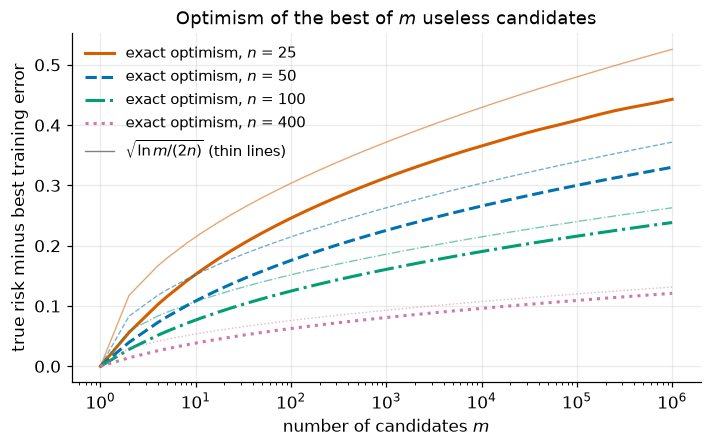

In [12]:
# Figure 3.4 — the optimism of the best of m useless candidates
def figure_3_4():
    ms = np.unique(np.logspace(0, 6, 40).astype(int))
    fig, ax = plt.subplots(figsize=(6.6, 4.2))
    styles = {25: (VERMILION, "-"), 50: (BLUE, "--"), 100: (GREEN, "-."), 400: (PURPLE, ":")}
    for n_, (color, ls) in styles.items():
        gap = [0.5 - expected_min_error(n_, m) for m in ms]
        ax.plot(ms, gap, color=color, linestyle=ls, linewidth=2, label=f"exact optimism, $n$ = {n_}")
        ax.plot(ms, np.sqrt(np.log(ms) / (2 * n_)), color=color, linestyle=ls, linewidth=0.9, alpha=0.55)
    ax.plot([], [], color="gray", linewidth=0.9, label=r"$\sqrt{\ln m/(2n)}$ (thin lines)")
    ax.set_xscale("log")
    ax.set(xlabel="number of candidates $m$", ylabel="true risk minus best training error",
           title="Optimism of the best of $m$ useless candidates")
    ax.legend(frameon=False, fontsize=9.5)
    fig.tight_layout()
    plt.show()


figure_3_4()

Two facts stand out. The optimism grows with the **logarithm** of the number of candidates (going from a hundred to a million candidates only doubles it), and it shrinks like $1/\sqrt{n}$ when the sample grows. That is the pattern of the theory we are about to develop, and it matches the thin curves of the formula $\sqrt{\ln m/(2n)}$, which will turn out to be an *upper bound* on this optimism that is nearly attained here.

:::{admonition} Pitfall — the winner's curse
:class: warning
Every time you compare many models, many hyperparameter values or many feature subsets **on the same data** and keep the best one, you are doing what the experiment above does with $m$ coin-flip classifiers: the winner's score is optimistic, and more so the more you tried. This is exactly the leakage of Section 2.7 (feature selection on the whole data set gave 82% accuracy on pure noise), seen from the theory side. The cure is also the same: keep data that played no role in the selection, a **validation set** or a **test set**, to measure the winner (Chapter 5).
:::

## 3.5 Concentration: from the law of large numbers to Hoeffding's inequality

The law of large numbers says that the empirical risk of a fixed function converges to its true risk, but it does not say **how fast**, and a guarantee that "eventually" holds is of little use for a data set of 500 examples. We need a statement of the form "with probability at least $1 - \delta$, the empirical risk is within $\varepsilon$ of the true one, as soon as $n$ is at least ...". Such statements are called **concentration inequalities**. We build them in three steps, from the crudest to the sharpest.

### 3.5.1 Markov and Chebyshev

**Markov's inequality.** If $Z \ge 0$ is a random variable and $t > 0$, then
$$
\mathbb{P}(Z \ge t) \le \frac{\mathbb{E}[Z]}{t}.
$$
*Proof.* $Z \ge t\,\mathbb{I}[Z \ge t]$ holds for every outcome, since $Z \ge 0$. Take expectations: $\mathbb{E}[Z] \ge t\,\mathbb{P}(Z \ge t)$. $\square$

Applied to $(Z - \mathbb{E}[Z])^2$ it gives **Chebyshev's inequality**, $\mathbb{P}(\lvert Z - \mathbb{E}[Z]\rvert \ge t) \le \operatorname{Var}(Z)/t^2$. For the mean $\bar X_n$ of $n$ independent variables with mean $\mu$ and variance $\sigma^2$, whose variance is $\sigma^2/n$ (Section 2.6.2),
$$
\mathbb{P}\big(\lvert \bar X_n - \mu\rvert \ge \varepsilon\big) \le \frac{\sigma^2}{n\varepsilon^2}.
$$
This is already a non-asymptotic statement, but the probability decays only like $1/n$: to be 99% sure we need a hundred times more data than to be 0% sure of nothing. We can do much better if the variables are **bounded**, as the losses of a classifier are.

### 3.5.2 The Chernoff method and Hoeffding's inequality

The idea of Chernoff is to apply Markov's inequality not to $Z$ but to $e^{sZ}$, for a free parameter $s > 0$ that we choose at the end: since $z \mapsto e^{sz}$ is increasing,
$$
\mathbb{P}(Z \ge t) = \mathbb{P}\big(e^{sZ} \ge e^{st}\big) \le e^{-st}\,\mathbb{E}\big[e^{sZ}\big].
$$
For a sum of *independent* variables, $\mathbb{E}[e^{s\sum_i Z_i}] = \prod_i \mathbb{E}[e^{sZ_i}]$ factorizes, and what remains is to bound the **moment generating function** $\mathbb{E}[e^{sZ_i}]$ of each term. For a bounded variable this is done by Hoeffding's lemma.

**Hoeffding's lemma.** If $\mathbb{E}[X] = 0$ and $a \le X \le b$, then for every $s \in \mathbb{R}$
$$
\mathbb{E}\big[e^{sX}\big] \le \exp\Big(\frac{s^2 (b - a)^2}{8}\Big).
$$

:::{admonition} Proof of Hoeffding's lemma (you may skip it)
:class: dropdown
Since $e^{sx}$ is a convex function of $x$, on the interval $[a, b]$ it lies below its chord: $e^{sx} \le \frac{b - x}{b - a} e^{sa} + \frac{x - a}{b - a} e^{sb}$. Taking expectations and using $\mathbb{E}[X] = 0$ (note that $a \le 0 \le b$),
$$
\mathbb{E}\big[e^{sX}\big] \le \frac{b}{b - a}\,e^{sa} - \frac{a}{b - a}\,e^{sb}.
$$
Let $p = -a/(b - a) \in [0, 1]$ and $u = s(b - a)$. Then $b/(b - a) = 1 - p$ and $sa = -pu$, so the right-hand side equals $e^{\varphi(u)}$ with
$$
\varphi(u) = -pu + \ln\big(1 - p + p\,e^{u}\big).
$$
Differentiate: $\varphi(0) = 0$, $\varphi'(u) = -p + \dfrac{p\,e^u}{1 - p + p\,e^u}$, so $\varphi'(0) = 0$, and
$$
\varphi''(u) = q(1 - q) \quad\text{with}\quad q = \frac{p\,e^u}{1 - p + p\,e^u} \in [0, 1],
$$
hence $\varphi''(u) \le \tfrac14$ for all $u$ (the maximum of $q(1-q)$ is $\tfrac14$). Taylor's theorem with the remainder gives $\varphi(u) = \varphi(0) + \varphi'(0)u + \tfrac12\varphi''(\xi)u^2 \le u^2/8$ for some $\xi$ between 0 and $u$. Therefore $\mathbb{E}[e^{sX}] \le e^{u^2/8} = e^{s^2(b-a)^2/8}$. $\square$
:::

**Hoeffding's inequality.** Let $X_1, \dots, X_n$ be independent with $X_i \in [a_i, b_i]$, and $S_n = \sum_{i} X_i$. Then for every $t > 0$
$$
\mathbb{P}\big(S_n - \mathbb{E}[S_n] \ge t\big) \le \exp\Big(-\frac{2t^2}{\sum_{i}(b_i - a_i)^2}\Big),
$$
and the same bound holds for the lower tail. In particular, for the **mean** of $n$ independent variables with values in $[0, 1]$ and expectation $\mu$,
$$
\mathbb{P}\big(\bar X_n - \mu \ge \varepsilon\big) \le e^{-2n\varepsilon^2}, \qquad
\mathbb{P}\big(\lvert \bar X_n - \mu\rvert \ge \varepsilon\big) \le 2\,e^{-2n\varepsilon^2}.
$$

:::{admonition} Proof of Hoeffding's inequality (you may skip it)
:class: dropdown
Apply the Chernoff method to $S_n - \mathbb{E}[S_n] = \sum_i (X_i - \mathbb{E}[X_i])$, whose terms are independent, have mean zero, and lie in an interval of length $b_i - a_i$. For any $s > 0$, by Markov's inequality, independence, and Hoeffding's lemma,
$$
\mathbb{P}\big(S_n - \mathbb{E}[S_n] \ge t\big) \le e^{-st}\prod_{i=1}^n \mathbb{E}\big[e^{s(X_i - \mathbb{E}X_i)}\big] \le \exp\Big(-st + \frac{s^2}{8}\sum_{i}(b_i - a_i)^2\Big).
$$
The exponent is a quadratic function of $s$, minimized at $s = 4t / \sum_i (b_i - a_i)^2$, where it equals $-2t^2/\sum_i (b_i - a_i)^2$. For the mean, take $t = n\varepsilon$ and $\sum_i (b_i - a_i)^2 = n$: the bound becomes $\exp(-2n^2\varepsilon^2/n) = e^{-2n\varepsilon^2}$. The two-sided bound adds the two tails. $\square$
:::

**From the inequality to a guarantee.** Fix a function $f$ *before seeing the data*, and let the loss be bounded in $[0, 1]$ (as the 0–1 loss is). The numbers $\ell(y_i, f(\mathbf{x}_i))$ are i.i.d. with values in $[0, 1]$ and mean $R(f)$, so
$$
\mathbb{P}\big(\lvert \hat{R}_S(f) - R(f)\rvert \ge \varepsilon\big) \le 2\,e^{-2n\varepsilon^2}.
$$
Setting the right-hand side equal to $\delta$ and solving for $\varepsilon$ gives the equivalent **confidence form**: with probability at least $1 - \delta$ over the draw of $S$,
$$
\boxed{\ \lvert \hat{R}_S(f) - R(f)\rvert \le \sqrt{\frac{\ln(2/\delta)}{2n}}\ }
$$
The deviation shrinks like $1/\sqrt{n}$ and grows only like $\sqrt{\ln(1/\delta)}$ when we ask for more confidence: **being very sure is cheap, being very precise is expensive.**

### 3.5.3 How good are these bounds?

Let us compare the bounds with the truth in a case where the truth can be computed exactly: the mean of $n$ Bernoulli($0.3$) variables, and the probability that it deviates from $0.3$ by at least $\varepsilon = 0.1$. The exact probability comes from the binomial distribution; we also show the Gaussian approximation of the central limit theorem (Section 2.6.6), which is accurate but is *not* a guarantee.

In [13]:
p_true, eps = 0.3, 0.1


def exact_tail(n):
    """P(|mean - p| >= eps) for the mean of n Bernoulli(p) variables, from the binomial distribution."""
    lo = np.floor(n * (p_true - eps) + 1e-9)             # k/n <= p - eps   <=>   k <= lo
    hi = np.ceil(n * (p_true + eps) - 1e-9)              # k/n >= p + eps   <=>   k >= hi
    return stats.binom.cdf(lo, n, p_true) + stats.binom.sf(hi - 1, n, p_true)


def tail_table(ns):
    ns = np.asarray(ns)
    return pd.DataFrame({
        "n": ns,
        "exact": [exact_tail(n) for n in ns],
        "CLT approximation": 2 * stats.norm.sf(eps * np.sqrt(ns) / np.sqrt(p_true * (1 - p_true))),
        "Hoeffding": np.minimum(1, 2 * np.exp(-2 * ns * eps ** 2)),
        "Chebyshev": np.minimum(1, p_true * (1 - p_true) / (ns * eps ** 2)),
    })


print(tail_table([10, 20, 50, 100, 200, 500, 1000]).to_string(index=False, float_format=lambda v: f"{v:.5f}"))

   n   exact  CLT approximation  Hoeffding  Chebyshev
  10 0.73317            0.49015    1.00000    1.00000
  20 0.46524            0.32911    1.00000    1.00000
  50 0.16365            0.12282    0.73576    0.42000
 100 0.03745            0.02910    0.27067    0.21000
 200 0.00257            0.00203    0.03663    0.10500
 500 0.00000            0.00000    0.00009    0.04200
1000 0.00000            0.00000    0.00000    0.02100


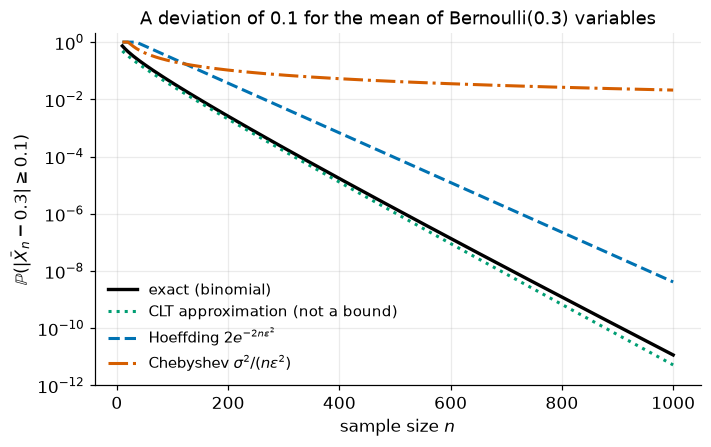

In [14]:
# Figure 3.5 — the probability of a deviation of 0.1: exact value and bounds
def figure_3_5():
    ns = np.arange(10, 1001, 5)
    tab = tail_table(ns)
    fig, ax = plt.subplots(figsize=(6.6, 4.2))
    ax.plot(tab["n"], tab["exact"], color="black", linewidth=2.2, label="exact (binomial)")
    ax.plot(tab["n"], tab["CLT approximation"], color=GREEN, linestyle=":", linewidth=2, label="CLT approximation (not a bound)")
    ax.plot(tab["n"], tab["Hoeffding"], color=BLUE, linestyle="--", linewidth=2, label=r"Hoeffding $2e^{-2n\varepsilon^2}$")
    ax.plot(tab["n"], tab["Chebyshev"], color=VERMILION, linestyle="-.", linewidth=2, label=r"Chebyshev $\sigma^2/(n\varepsilon^2)$")
    ax.set_yscale("log")
    ax.set_ylim(1e-12, 2)
    ax.set(xlabel="sample size $n$", ylabel=r"$\mathbb{P}(|\bar X_n - 0.3| \geq 0.1)$",
           title="A deviation of 0.1 for the mean of Bernoulli(0.3) variables")
    ax.legend(frameon=False, fontsize=9.5, loc="lower left")
    fig.tight_layout()
    plt.show()


figure_3_5()

On the logarithmic scale of Figure 3.5 an exponential decay is a straight line. The exact probability (black) decays exponentially, and **Hoeffding's bound (blue dashed) decays at nearly the same exponential rate**, staying above the truth by a modest factor: it is a *guarantee* that is also informative. Chebyshev's bound (vermilion) decays only polynomially and is useless for large $n$, though it is better than Hoeffding's for $n$ up to about 100 in this table, because Hoeffding uses only the *range* of the variables, while Chebyshev uses their variance (0.21 here, less than the worst case 0.25 of the range $[0, 1]$). There are sharper inequalities that use both (Bernstein's, Bennett's); we do not need them. The Gaussian approximation (green dotted) is the closest to the truth for moderate $n$, but it carries no guarantee: it is an approximation, not an inequality.

### Worked example 3.2 — how many coin flips?

We want to estimate the probability $p$ that a coin lands heads, to within $\varepsilon = 0.05$, with confidence $1 - \delta = 0.99$. By Hoeffding, it suffices that $2e^{-2n\varepsilon^2} \le \delta$, that is
$$
n \ge \frac{\ln(2/\delta)}{2\varepsilon^2} = \frac{\ln 200}{2 \cdot 0.0025} = \frac{5.298}{0.005} \approx 1059.7 \quad\Longrightarrow\quad n = 1060.
$$
Chebyshev, in the worst case $\sigma^2 = \tfrac14$, requires $n \ge \frac{1/4}{\varepsilon^2\delta} = 10{,}000$. The central limit theorem suggests $n \approx (z_{0.995}\,\sigma/\varepsilon)^2 = (2.576 \cdot 0.5/0.05)^2 \approx 664$, a number that is *right for large $n$ but is not guaranteed*. Let us compute the three.

In [15]:
eps_c, delta_c = 0.05, 0.01
n_hoeffding = int(np.ceil(np.log(2 / delta_c) / (2 * eps_c ** 2)))
n_chebyshev = int(np.ceil(0.25 / (eps_c ** 2 * delta_c)))
n_clt = int(np.ceil((stats.norm.ppf(1 - delta_c / 2) * 0.5 / eps_c) ** 2))
print(f"Hoeffding (guaranteed)            : n >= {n_hoeffding}")
print(f"Chebyshev (guaranteed, worst case): n >= {n_chebyshev}")
print(f"CLT (approximate)                 : n >= {n_clt}")

# A sanity check of the Hoeffding sample size by simulation (the worst case is p = 1/2)
rng = np.random.default_rng(SEED)
for n_try in (n_clt, n_hoeffding):
    means = rng.binomial(n_try, 0.5, size=200_000) / n_try
    print(f"n = {n_try:>4}: fraction of 200,000 repetitions with |mean - 0.5| > 0.05: {np.mean(np.abs(means - 0.5) > eps_c):.5f}   (target: at most {delta_c})")

Hoeffding (guaranteed)            : n >= 1060
Chebyshev (guaranteed, worst case): n >= 10000
CLT (approximate)                 : n >= 664
n =  664: fraction of 200,000 repetitions with |mean - 0.5| > 0.05: 0.00945   (target: at most 0.01)
n = 1060: fraction of 200,000 repetitions with |mean - 0.5| > 0.05: 0.00111   (target: at most 0.01)


With $n = 1060$ the failure rate is far below the 1% we allowed: Hoeffding's guarantee is **conservative**, because it is valid for *every* distribution on $[0, 1]$. The CLT sample size of 664 gives a failure rate close to the nominal 1%, but that holds only because the Gaussian approximation is excellent for a Bernoulli(½) with $n \approx 664$; for rare events (a probability of 0.01, say) it is much worse.

:::{admonition} Key idea
:class: tip
**Hoeffding's inequality is the engine of generalization theory.** It turns "the average of $n$ bounded independent variables" into "within $\sqrt{\ln(2/\delta)/(2n)}$ of its mean, with probability at least $1 - \delta$". It requires only independence and boundedness: no Gaussianity, no knowledge of the variance. Its two limitations are the topic of the next sections. It speaks about **one function fixed in advance** (Section 3.6 handles the function chosen by ERM), and it needs a **bounded loss** (for the squared loss, one needs other tools, which exist but are beyond this book).
:::

## 3.6 Learning with a finite hypothesis class

Section 3.4 showed that Hoeffding's guarantee for one fixed function cannot be applied to $\hat f_S$, because $\hat f_S$ was chosen with the help of the data. The remedy is to ask for more: a bound that holds **simultaneously for all** functions of $\mathcal{H}$, hence also for the one that the data selected. For a finite class the **union bound** does it: for any events $A_1, \dots, A_m$,
$$
\mathbb{P}\Big(\bigcup_{j=1}^m A_j\Big) \le \sum_{j=1}^m \mathbb{P}(A_j).
$$
Let $\mathcal{H}$ be a finite set with $\lvert\mathcal{H}\rvert$ functions and let the loss take values in $[0, 1]$.

**Theorem 3.1 (uniform deviation for a finite class).** For every $\delta \in (0, 1)$, with probability at least $1 - \delta$ over the draw of the training set $S$ of $n$ i.i.d. examples, **all** functions $f \in \mathcal{H}$ satisfy
$$
\boxed{\ \lvert R(f) - \hat{R}_S(f)\rvert \le \sqrt{\frac{\ln\lvert\mathcal{H}\rvert + \ln(2/\delta)}{2n}}\ }
$$

*Proof.* Let $\varepsilon$ denote the right-hand side. For each fixed $f$, Hoeffding's inequality gives $\mathbb{P}(\lvert R(f) - \hat{R}_S(f)\rvert > \varepsilon) \le 2e^{-2n\varepsilon^2} = \delta/\lvert\mathcal{H}\rvert$, because $2n\varepsilon^2 = \ln\lvert\mathcal{H}\rvert + \ln(2/\delta)$. By the union bound over the $\lvert\mathcal{H}\rvert$ functions, the probability that *at least one* of them deviates by more than $\varepsilon$ is at most $\lvert\mathcal{H}\rvert \cdot \delta / \lvert\mathcal{H}\rvert = \delta$. $\square$

The price of uniformity is the term $\ln\lvert\mathcal{H}\rvert$: the size of the class enters **only through its logarithm**. A class with a million functions costs $\ln 10^6 \approx 13.8$; a class with $10^{100}$ functions costs $230$. This is the mathematical form of the optimism of Section 3.4.1, and it explains why the curves of Figure 3.4 grew like $\sqrt{\ln m}$.

**Corollary 3.2 (what ERM guarantees).** On the event of Theorem 3.1, with $\varepsilon$ its right-hand side, the ERM solution satisfies
$$
R(\hat f_S) \le R(f_{\mathcal{H}}) + 2\varepsilon, \qquad\text{that is,}\qquad \text{estimation error} \le 2\sqrt{\frac{\ln\lvert\mathcal{H}\rvert + \ln(2/\delta)}{2n}}.
$$

*Proof.* Three inequalities, in a chain: $R(\hat f_S) \le \hat{R}_S(\hat f_S) + \varepsilon$ (uniform deviation, applied to $\hat f_S$), then $\hat{R}_S(\hat f_S) \le \hat{R}_S(f_{\mathcal{H}})$ (definition of ERM), then $\hat{R}_S(f_{\mathcal{H}}) \le R(f_{\mathcal{H}}) + \varepsilon$ (uniform deviation, applied to $f_{\mathcal{H}}$). $\square$

So the estimation error of ERM over a finite class shrinks like $\sqrt{\ln\lvert\mathcal{H}\rvert / n}$: **the more candidates, the more data are needed, but only logarithmically in the number of candidates.** Inverting the formulas gives the **sample complexity**: to have all deviations at most $\varepsilon$, or an estimation error at most $\varepsilon$ (which needs deviations of $\varepsilon/2$), it suffices that
$$
n \ge \frac{\ln\lvert\mathcal{H}\rvert + \ln(2/\delta)}{2\varepsilon^2}
\qquad\text{or}\qquad
n \ge \frac{2\,\big(\ln\lvert\mathcal{H}\rvert + \ln(2/\delta)\big)}{\varepsilon^2}
\quad\text{respectively.}
$$

### Worked example 3.3 — a class described by 20 bits

Suppose the hypotheses are the classifiers that can be described by 20 binary choices (for instance, 20 yes/no design decisions), so that $\lvert\mathcal{H}\rvert = 2^{20} \approx 10^6$. How many examples guarantee, with probability 0.99, that every empirical risk is within $\varepsilon = 0.05$ of the true one?
$$
n \ge \frac{20\ln 2 + \ln 200}{2 \cdot 0.05^2} = \frac{13.863 + 5.298}{0.005} \approx 3832.2 \quad\Longrightarrow\quad n = 3833.
$$
To guarantee an *estimation error* of 0.05 for ERM we need four times as many: $n \ge 2 \cdot 19.161/0.0025 \approx 15{,}329$, that is $n = 15{,}330$. Notice the shape of the result: a model that is described by $b$ bits has $\ln\lvert\mathcal{H}\rvert = b \ln 2$, so the required number of examples grows **linearly with the number of bits**, and a model with $p$ real parameters stored with 32 bits has at most $2^{32p}$ different functions, so $n$ grows linearly with the number of parameters $p$. This is the first appearance of a rule that we will meet again in a sharper form: *the number of examples must be larger than the capacity of the model*.

In [16]:
def n_uniform(log_h, eps, delta, estimation=False):
    """Sample size from Theorem 3.1 (uniform deviation <= eps) or from Corollary 3.2 (estimation error <= eps)."""
    base = (log_h + np.log(2 / delta)) / (2 * eps ** 2)
    return int(np.ceil(4 * base if estimation else base))


print("|H| = 2^20, eps = 0.05, delta = 0.01")
print("  uniform deviation <= 0.05    :", n_uniform(20 * np.log(2), 0.05, 0.01))
print("  ERM estimation error <= 0.05 :", n_uniform(20 * np.log(2), 0.05, 0.01, estimation=True))
for p_params in (10, 100, 1000):
    print(f"a model with {p_params:>4} parameters of 32 bits: n >= {n_uniform(32 * p_params * np.log(2), 0.05, 0.01):,}")

|H| = 2^20, eps = 0.05, delta = 0.01
  uniform deviation <= 0.05    : 3833
  ERM estimation error <= 0.05 : 15330
a model with   10 parameters of 32 bits: n >= 45,422
a model with  100 parameters of 32 bits: n >= 444,674
a model with 1000 parameters of 32 bits: n >= 4,437,202


### 3.6.1 An experiment on real data: decision stumps

A **decision stump** is the simplest classifier on a table: it looks at one feature, compares it with a threshold, and predicts one class on each side. On the Breast Cancer data we build a finite class $\mathcal{H}$ by taking each of the 30 features, 19 thresholds (the 5th, 10th, ..., 95th percentiles of the feature) and 2 possible orientations: $\lvert\mathcal{H}\rvert = 30 \cdot 19 \cdot 2 = 1140$ stumps.

To check Theorem 3.1 we need to **know the true risk** of every stump, which requires knowing $\mathcal{D}$. We therefore declare that $\mathcal{D}$ is the **empirical distribution of the 569 patients**, which puts probability $1/569$ on each patient. The true risk of a stump is then its error rate on the 569 patients, computed exactly, and a "training set" of size $n$ is $n$ patients drawn **with replacement** (so the draws are i.i.d. from $\mathcal{D}$, as the theory requires; $n$ may even exceed 569). This is a standard device, called the **bootstrap world**: a real data set, with a population that we know completely.

In [17]:
from sklearn.datasets import load_breast_cancer

bc = load_breast_cancer()
X_bc, y_bc = bc.data, bc.target
N_BC, D_BC = X_bc.shape

# The finite class of stumps: one column of ERR per stump, holding 1 where the stump errs on a patient
columns, stump_info = [], []
for j in range(D_BC):
    for thr in np.quantile(X_bc[:, j], np.linspace(0.05, 0.95, 19)):
        for orientation in (0, 1):
            pred = (X_bc[:, j] > thr) if orientation == 0 else (X_bc[:, j] <= thr)
            columns.append(pred.astype(int) != y_bc)
            stump_info.append((j, thr, orientation))
ERR = np.array(columns).T.astype(float)              # shape (569, 1140)
R_TRUE = ERR.mean(axis=0)                            # the exact true risk of every stump under D
H_SIZE = ERR.shape[1]
best = R_TRUE.argmin()
print(f"|H| = {H_SIZE} stumps | best stump: feature '{bc.feature_names[stump_info[best][0]]}', true risk {R_TRUE[best]:.4f}")

|H| = 1140 stumps | best stump: feature 'worst perimeter', true risk 0.0826


In [18]:
def uniform_bound(n, h_size, delta=0.05):
    return np.sqrt((np.log(h_size) + np.log(2 / delta)) / (2 * n))


rng = np.random.default_rng(SEED)
delta_s = 0.05
rows = []
for n in [20, 50, 100, 200, 500, 1000, 2000]:
    counts = rng.multinomial(n, np.ones(N_BC) / N_BC, size=3000)     # 3000 training sets of n patients, with replacement
    R_hat = counts @ ERR / n                                         # empirical risk of every stump on every training set
    sup_dev = np.abs(R_hat - R_TRUE).max(axis=1)                     # largest deviation over the whole class
    erm = R_hat.argmin(axis=1)                                       # ERM stump of each training set
    bound = uniform_bound(n, H_SIZE, delta_s)
    rows.append({"n": n, "95th percentile of sup deviation": np.quantile(sup_dev, 1 - delta_s), "Theorem 3.1 bound": bound,
                 "runs above the bound": np.mean(sup_dev > bound), "training error of ERM": R_hat.min(axis=1).mean(),
                 "true risk of ERM": R_TRUE[erm].mean(), "best stump": R_TRUE.min()})
stump_results = pd.DataFrame(rows)
print(stump_results.round(4).to_string(index=False))

   n  95th percentile of sup deviation  Theorem 3.1 bound  runs above the bound  training error of ERM  true risk of ERM  best stump
  20                            0.3765             0.5179                0.0000                 0.0187            0.1359      0.0826
  50                            0.2403             0.3275                0.0010                 0.0423            0.1039      0.0826
 100                            0.1733             0.2316                0.0007                 0.0554            0.0941      0.0826
 200                            0.1220             0.1638                0.0003                 0.0651            0.0897      0.0826
 500                            0.0764             0.1036                0.0003                 0.0735            0.0874      0.0826
1000                            0.0537             0.0732                0.0003                 0.0773            0.0863      0.0826
2000                            0.0385             0.0518            

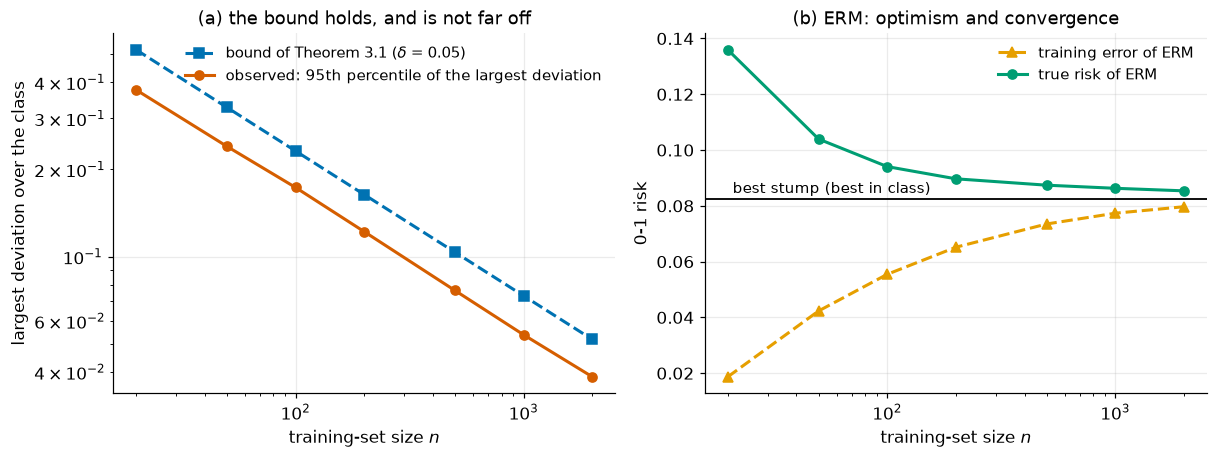

In [19]:
# Figure 3.6 — finite-class theory on the stumps of the Breast Cancer data
def figure_3_6():
    r = stump_results
    fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.3))

    ax = axes[0]
    ax.plot(r["n"], r["Theorem 3.1 bound"], color=BLUE, marker="s", linestyle="--", linewidth=2, label="bound of Theorem 3.1 ($\\delta$ = 0.05)")
    ax.plot(r["n"], r["95th percentile of sup deviation"], color=VERMILION, marker="o", linewidth=2, label="observed: 95th percentile of the largest deviation")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set(xlabel="training-set size $n$", ylabel="largest deviation over the class", title="(a) the bound holds, and is not far off")
    ax.legend(frameon=False, fontsize=9.5)

    ax = axes[1]
    ax.plot(r["n"], r["training error of ERM"], color=ORANGE, marker="^", linestyle="--", linewidth=2, label="training error of ERM")
    ax.plot(r["n"], r["true risk of ERM"], color=GREEN, marker="o", linewidth=2, label="true risk of ERM")
    ax.axhline(R_TRUE.min(), color="black", linewidth=1.2)
    ax.text(21, R_TRUE.min() + 0.002, "best stump (best in class)", fontsize=9.5)
    ax.set_xscale("log")
    ax.set(xlabel="training-set size $n$", ylabel="0-1 risk", title="(b) ERM: optimism and convergence")
    ax.legend(frameon=False, fontsize=9.5, loc="upper right")
    fig.tight_layout()
    plt.show()


figure_3_6()

Four observations.

1. **The bound is valid.** The largest deviation exceeds the bound of Theorem 3.1 in a tiny fraction of the runs (column "runs above the bound"), far below the 5% that we allowed. This is not a coincidence: the guarantee uses Hoeffding's inequality and the union bound, both of which are conservative.
2. **The bound is not far from the truth**, within a factor 1.3 to 1.4 at every sample size, and it has the right shape, $1/\sqrt{n}$. Stumps on correlated features behave as if the class had fewer than 1140 independent members, which is one reason the bound is not attained.
3. **The training error is optimistic, the test error is pessimistic, and they close in on the best stump from opposite sides** (panel b): this is the chain of inequalities of Section 3.4 made visible. With $n = 100$ the ERM stump has a training error of 5.5% but a true risk of 9.4%.
4. **The ERM guarantee of Corollary 3.2 is very loose here.** On average, the *excess* risk of the ERM stump over the best stump is below 0.005 for $n = 500$, while the guarantee $2\varepsilon$ is 0.21 at that sample size. The guarantee is about the *worst* case, and our real data are not that bad.

:::{admonition} Try it
:class: note
Make the class smaller (use 5 thresholds per feature instead of 19) or larger (use 99 thresholds). By how much does the bound of Theorem 3.1 change? Does the observed deviation change by a comparable amount? Since the bound depends on the class only through $\ln\lvert\mathcal{H}\rvert$, multiplying the number of stumps by five should increase it by a small factor.
:::

## 3.7 Infinite classes: the VC dimension

Theorem 3.1 is of no use for the most important classes of the book: there are infinitely many lines in the plane, so $\ln\lvert\mathcal{H}\rvert = \infty$. Yet the lines are clearly less flexible than "all functions", and the experiments of Section 3.3 showed that a class with 5 features behaves very differently from one with 44. We need a measure of the *effective* size of a class. The key observation is that a sample of $n$ points can only distinguish between the **different label vectors that the class produces on those $n$ points**. There are at most $2^n$ of them, no matter how large $\mathcal{H}$ is. If a class produces *fewer* than $2^n$, the class is not completely flexible on $n$ points, and the count of label vectors can play the role of $\lvert\mathcal{H}\rvert$.

### 3.7.1 Dichotomies, growth function, shattering

Throughout this section the labels are binary and the loss is the 0–1 loss. For $n$ points $\mathbf{x}_1, \dots, \mathbf{x}_n$, the set of **dichotomies** (labelings) that $\mathcal{H}$ can produce on them is
$$
\mathcal{H}(\mathbf{x}_1, \dots, \mathbf{x}_n) = \big\{(f(\mathbf{x}_1), \dots, f(\mathbf{x}_n)) : f \in \mathcal{H}\big\} \subseteq \{0, 1\}^n .
$$
The **growth function** is the largest number of dichotomies on any $n$ points,
$$
\Pi_{\mathcal{H}}(n) = \max_{\mathbf{x}_1, \dots, \mathbf{x}_n}\ \big\lvert \mathcal{H}(\mathbf{x}_1, \dots, \mathbf{x}_n)\big\rvert \ \le\ 2^n .
$$
A set of $n$ points is **shattered** by $\mathcal{H}$ if $\mathcal{H}$ produces all $2^n$ labelings on it. The **VC dimension** (Vapnik–Chervonenkis dimension) of $\mathcal{H}$, written $d_{\mathrm{VC}}$, is the size of the largest set that $\mathcal{H}$ can shatter, that is, the largest $n$ with $\Pi_{\mathcal{H}}(n) = 2^n$; it is $\infty$ if arbitrarily large sets can be shattered.

Two words of caution. To show that $d_{\mathrm{VC}} \ge d$ it is enough to find **one** set of $d$ points that can be shattered. To show that $d_{\mathrm{VC}} < d + 1$ we must show that **no** set of $d + 1$ points can be shattered. The two tasks are not symmetric.

### Worked example 3.4 — intervals on a line

Let $\mathcal{H}$ be the intervals of the real line, $f_{a, b}(x) = \mathbb{I}[a \le x \le b]$: a point gets label 1 inside the interval and 0 outside. Take $n$ distinct points and sort them, $x_1 < \dots < x_n$. A labeling is produced by some interval if and only if its ones are **consecutive** (a single block of ones, or no ones at all). A block is determined by where it starts and where it ends, which is a choice of two of the $n + 1$ "gaps" between consecutive points (counting the two ends), so there are $\binom{n+1}{2} = \tfrac{n(n+1)}{2}$ non-empty blocks, plus the empty labeling:
$$
\Pi_{\mathcal{H}}(n) = \frac{n(n+1)}{2} + 1 .
$$
For $n = 2$ this is $4 = 2^2$: two points are shattered. For $n = 3$ it is $7 < 8$: the labeling $(1, 0, 1)$ cannot be produced, since a single interval that contains $x_1$ and $x_3$ also contains $x_2$. Hence $d_{\mathrm{VC}} = 2$ for the intervals. The same reasoning shows $d_{\mathrm{VC}} = 1$ for the *half-lines* $\mathbb{I}[x > t]$, whose growth function is $n + 1$. Let us verify the count by brute force.

In [20]:
def count_dichotomies_intervals(n):
    """Distinct label vectors produced on the points 0, 1, ..., n-1 by the intervals [a, b] (and the empty interval)."""
    xs = np.arange(n)
    ends = np.arange(-0.5, n, 1.0)                      # an interval end can sit in any of the n + 1 gaps
    labelings = {tuple((xs >= a) & (xs <= b)) for a in ends for b in ends}   # a > b gives the empty interval
    return len(labelings)


pd.DataFrame({"n": range(1, 9),
              "2^n": [2 ** k for k in range(1, 9)],
              "intervals, counted": [count_dichotomies_intervals(k) for k in range(1, 9)],
              "n(n+1)/2 + 1": [k * (k + 1) // 2 + 1 for k in range(1, 9)]}).set_index("n")

,2^n,"intervals, counted",n(n+1)/2 + 1
n,,,
1,2,2,2
2,4,4,4
3,8,7,7
4,16,11,11
5,32,16,16
6,64,22,22
7,128,29,29
8,256,37,37


The counted values coincide with the formula; they equal $2^n$ for $n = 1, 2$ and fall below it from $n = 3$ on. After the first failure the growth function becomes a *polynomial* in $n$ (here quadratic), while $2^n$ is exponential: this is the general pattern that Theorem 3.3 will state.

### 3.7.2 Linear classifiers in the plane and in $\mathbb{R}^d$

Consider the classifiers $f(\mathbf{x}) = \mathbb{I}[\mathbf{w}^\top\mathbf{x} + b > 0]$ on $\mathbb{R}^d$ (**linear classifiers**, or half-spaces). In the plane ($d = 2$) any **three** points that are not on a line can be shattered: whichever subset of them we want to label 1, a line separates it from the rest. **Four** points cannot be shattered. If they form the corners of a square and we label opposite corners alike (the XOR pattern of Section 1.3), no line separates the two classes; and for four points in any other position some other labeling fails. So $d_{\mathrm{VC}} = 3 = d + 1$ in the plane.

The general statement is a classical theorem of Cover (1965), which counts exactly how many of the $2^n$ labelings of $n$ points **in general position** (no $d + 1$ of them on a common hyperplane, the typical situation) are produced by half-spaces of $\mathbb{R}^d$:
$$
\Pi(n) = 2\sum_{k=0}^{d}\binom{n - 1}{k}. \qquad\text{(Cover)}
$$
For $n \le d + 1$ the sum contains all the binomial coefficients and equals $2 \cdot 2^{n-1} = 2^n$: all labelings are possible. For $n = d + 2$ it is $2^n - 2$: exactly two labelings are lost. Hence $d_{\mathrm{VC}} = d + 1$: **a linear classifier in $\mathbb{R}^d$ has $d + 1$ degrees of freedom (the weights and the bias), and that is also its VC dimension.**

We can check Cover's formula numerically, because deciding whether a labeling is realized by a line is a **linear program**: we look for $(\mathbf{w}, b)$ with $y_i(\mathbf{w}^\top\mathbf{x}_i + b) \ge 1$ for all $i$ (with labels $y_i \in \{-1, +1\}$; the margin 1 is only a normalization, since any separating $\mathbf{w}, b$ can be rescaled). The function `is_separable` below solves it with `scipy.optimize.linprog`, and we count the separable labelings of random points.

In [21]:
from itertools import product
from math import comb

from scipy.optimize import linprog


def is_separable(X, y):
    """Is there (w, b) with y_i (w.x_i + b) >= 1 for every i?  y in {-1, +1}. A feasibility linear program."""
    n, d = X.shape
    A_ub = -(y[:, None] * np.hstack([X, np.ones((n, 1))]))          # -y_i (x_i, 1) . (w, b) <= -1
    res = linprog(np.zeros(d + 1), A_ub=A_ub, b_ub=-np.ones(n), bounds=[(None, None)] * (d + 1), method="highs")
    return res.status == 0


def cover_count(n, d):
    return 2 * sum(comb(n - 1, k) for k in range(d + 1))


rng = np.random.default_rng(SEED)
rows = []
for d in (2, 3):
    for n in range(2, 10):
        X = rng.normal(size=(n, d))                                  # random points are in general position
        counted = sum(is_separable(X, np.array(labels)) for labels in product([-1, 1], repeat=n))
        rows.append({"d": d, "n": n, "2^n": 2 ** n, "separable labelings (counted)": counted, "Cover's formula": cover_count(n, d)})
growth_table = pd.DataFrame(rows)
print(growth_table.to_string(index=False))

 d  n  2^n  separable labelings (counted)  Cover's formula
 2  2    4                              4                4
 2  3    8                              8                8
 2  4   16                             14               14
 2  5   32                             22               22
 2  6   64                             32               32
 2  7  128                             44               44
 2  8  256                             58               58
 2  9  512                             74               74
 3  2    4                              4                4
 3  3    8                              8                8
 3  4   16                             16               16
 3  5   32                             30               30
 3  6   64                             52               52
 3  7  128                             84               84
 3  8  256                            128              128
 3  9  512                            186              1

The counted numbers agree with Cover's formula in every row. In the plane ($d = 2$), the number of separable labelings is $8 = 2^3$ for three points, but only $14$ of $16$ for four points, $22$ of $32$ for five, $58$ of $256$ for eight: after $n = 3$ the fraction of realizable labelings collapses. In space ($d = 3$) the first loss appears at $n = 5$ (30 of 32). The class is as rich as its dimension says, and no richer.

### 3.7.3 A linear classifier can fit pure noise

A direct consequence of Cover's formula is a result that explains Section 3.4 for linear models. Take $n$ points in general position and give them **random labels**: no relation between inputs and labels, nothing to learn. The probability that a *linear classifier in $\mathbb{R}^d$ can still reproduce the labels exactly*, hence achieve a training error of zero, is the fraction of realizable labelings:
$$
\mathbb{P}(\text{separable}) = \frac{\Pi(n)}{2^n} = \frac{2}{2^{n}}\sum_{k=0}^{d}\binom{n-1}{k} = \mathbb{P}\big(\mathrm{Bin}(n - 1, \tfrac12) \le d\big).
$$
The last equality says that the transition is governed by a binomial distribution centered at $(n-1)/2$: the probability is small when $d < n/2 - 1$, one half at $d \approx n/2$, and close to one once $d$ is a few standard deviations ($\sqrt{n}/2$) larger. **A linear classifier can memorize random labels as soon as it has about half as many features as there are examples.** We test the prediction with $n = 40$ points and random labels, for dimensions $d$ from 5 to 39, with 150 random trials each.

In [22]:
n_noise = 40
rng = np.random.default_rng(SEED)
dims = [5, 10, 15, 18, 19, 20, 21, 22, 25, 30, 39]
rows = []
for d in dims:
    hits = 0
    for _ in range(150):
        X = rng.normal(size=(n_noise, d))
        y = rng.choice([-1, 1], size=n_noise)                        # pure noise: the labels ignore the features
        hits += is_separable(X, y)
    rows.append({"dimension d": d, "fraction of noise sets fitted perfectly": hits / 150,
                 "theory: P(Bin(39, 1/2) <= d)": stats.binom.cdf(d, n_noise - 1, 0.5)})
noise_table = pd.DataFrame(rows)
print(noise_table.round(3).to_string(index=False))

 dimension d  fraction of noise sets fitted perfectly  theory: P(Bin(39, 1/2) <= d)
           5                                    0.000                         0.000
          10                                    0.000                         0.002
          15                                    0.127                         0.100
          18                                    0.387                         0.375
          19                                    0.507                         0.500
          20                                    0.593                         0.625
          21                                    0.707                         0.739
          22                                    0.827                         0.832
          25                                    0.973                         0.973
          30                                    1.000                         1.000
          39                                    1.000                       

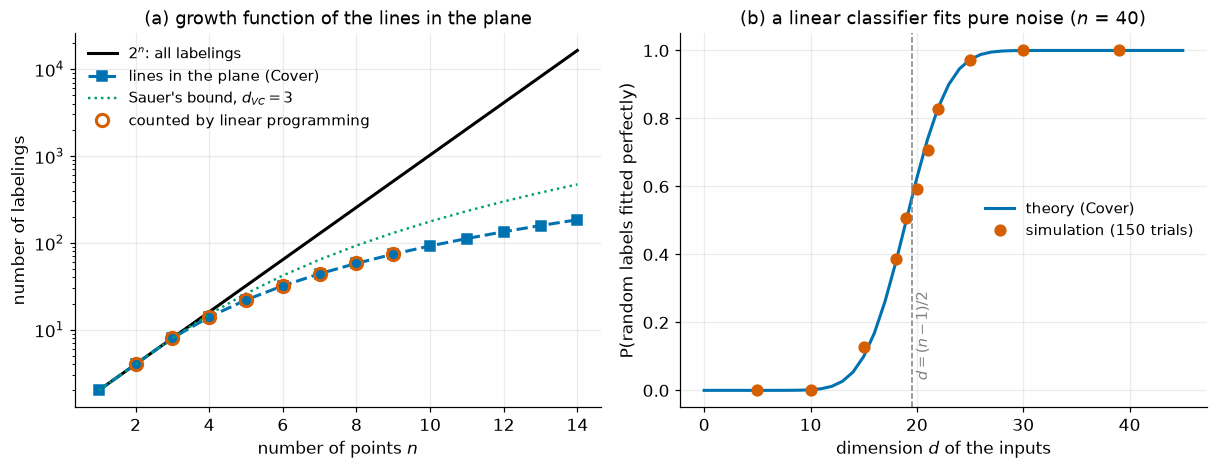

In [23]:
# Figure 3.7 — growth function of the lines in the plane, and the transition at which a linear classifier fits noise
def figure_3_7():
    fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.4))

    ax = axes[0]
    ns = np.arange(1, 15)
    ax.plot(ns, 2.0 ** ns, color="black", linewidth=2, label="$2^n$: all labelings")
    ax.plot(ns, [cover_count(n, 2) for n in ns], color=BLUE, linewidth=2, marker="s", linestyle="--", label="lines in the plane (Cover)")
    ax.plot(ns, [sum(comb(n, k) for k in range(4)) for n in ns], color=GREEN, linewidth=1.6, linestyle=":", label=r"Sauer's bound, $d_{VC}=3$")
    sub = growth_table[growth_table["d"] == 2]
    ax.plot(sub["n"], sub["separable labelings (counted)"], color=VERMILION, linestyle="none", marker="o", markersize=8,
            markerfacecolor="none", markeredgewidth=2, label="counted by linear programming")
    ax.set_yscale("log")
    ax.set(xlabel="number of points $n$", ylabel="number of labelings", title="(a) growth function of the lines in the plane")
    ax.legend(frameon=False, fontsize=9.5, loc="upper left")

    ax = axes[1]
    d_grid = np.arange(0, 46)
    ax.plot(d_grid, stats.binom.cdf(d_grid, n_noise - 1, 0.5), color=BLUE, linewidth=2, label="theory (Cover)")
    ax.plot(noise_table["dimension d"], noise_table["fraction of noise sets fitted perfectly"], color=VERMILION, linestyle="none",
            marker="o", markersize=7, label="simulation (150 trials)")
    ax.axvline((n_noise - 1) / 2, color="gray", linestyle="--", linewidth=1)
    ax.text(19.9, 0.04, "$d = (n-1)/2$", rotation=90, ha="left", color="gray", fontsize=9.5)
    ax.set(xlabel="dimension $d$ of the inputs", ylabel="P(random labels fitted perfectly)",
           title=f"(b) a linear classifier fits pure noise ($n$ = {n_noise})")
    ax.legend(frameon=False, fontsize=9.5, loc="center right")
    fig.tight_layout()
    plt.show()


figure_3_7()

Panel (a): the number of labelings of the lines follows $2^n$ up to $n = 3$ (the points of the table and the dashed line coincide with the black curve) and then bends away, growing only like $n^2$. Panel (b): the simulation (circles) lies on Cover's curve. For $d = 5$ or $10$ a linear classifier never fits 40 random labels; at $d = 19$, about half the time; for $d = 30$ always. **This is the mathematical mechanism of overfitting in linear models**: with $d$ comparable to $n$ the classifier has enough freedom to fit anything, noise included, and a perfect training score proves nothing (compare with the optimism of Section 3.4 and with the experiment of Section 2.7, where we selected 10 features out of 2000 on pure noise).

### 3.7.4 The Sauer–Shelah lemma and the VC bound

In the intervals and the lines, the growth function equals $2^n$ for a while and then becomes polynomial. This is a theorem: it holds for every class.

**Theorem 3.3 (Sauer–Shelah lemma).** If $\mathcal{H}$ has VC dimension $d < \infty$, then for every $n \ge d$
$$
\Pi_{\mathcal{H}}(n) \le \sum_{k=0}^{d}\binom{n}{k} \le \Big(\frac{e\,n}{d}\Big)^{d}.
$$
(We omit the proof, a short induction; see the book of Shalev-Shwartz and Ben-David.) There is **no intermediate regime**: a class either shatters sets of every size ($d_{\mathrm{VC}} = \infty$, and then no uniform guarantee is possible) or its growth function is bounded by a polynomial of degree $d_{\mathrm{VC}}$. A polynomial in $n$ has a *logarithm* that grows like $d \ln n$, which is exactly what is needed to replace $\ln\lvert\mathcal{H}\rvert$ in Theorem 3.1.

**Theorem 3.4 (VC generalization bound; Vapnik and Chervonenkis, 1971).** Let $\mathcal{H}$ have VC dimension $d < \infty$, and let the loss be the 0–1 loss. For every $\delta \in (0, 1)$, with probability at least $1 - \delta$ over the draw of $S$, **all** $f \in \mathcal{H}$ satisfy, for $n \ge d$,
$$
R(f) \le \hat{R}_S(f) + \sqrt{\frac{8}{n}\Big(d\,\ln\frac{2en}{d} + \ln\frac{4}{\delta}\Big)}.
$$
The proof replaces the union bound over $\lvert\mathcal{H}\rvert$ functions by one over the $\Pi_{\mathcal{H}}(2n)$ dichotomies on a *double sample* of $2n$ points (a "symmetrization" argument) and then applies Theorem 3.3; it is beyond the scope of this book (see the Further reading). The constants (8, 4, 2) differ in different textbooks and do not matter; the *structure* does:

- the complexity term grows like $\sqrt{d\ln n / n}$: the number of examples must be **larger than the VC dimension**, which for linear classifiers is the number of features plus one;
- the class enters only through $d_{\mathrm{VC}}$, so the bound holds for **every** distribution $\mathcal{D}$ and any algorithm that picks a function of $\mathcal{H}$;
- a rule of thumb that comes out of it, and is often quoted, is that one needs on the order of **ten examples per unit of VC dimension** for the guarantee to be meaningful. We now see how meaningful it is.

In [24]:
def vc_term(n, d_vc, delta=0.05):
    """The complexity term of Theorem 3.4 (valid for n >= d_vc)."""
    n = np.asarray(n, dtype=float)
    return np.sqrt(8 / n * (d_vc * np.log(2 * np.e * n / d_vc) + np.log(4 / delta)))


def first_n_below(d_vc, level):
    grid = np.logspace(np.log10(d_vc), 10, 40_000)
    return grid[np.argmax(vc_term(grid, d_vc) <= level)]


rows = []
for d_vc in (3, 11, 31, 101):
    rows.append({"VC dimension": d_vc, "term at n = 455": float(vc_term(455, d_vc)),
                 "n needed for term <= 0.5": first_n_below(d_vc, 0.5), "n needed for term <= 0.1": first_n_below(d_vc, 0.1)})
vc_table = pd.DataFrame(rows)
print(vc_table.round(2).to_string(index=False, formatters={"n needed for term <= 0.5": "{:,.0f}".format, "n needed for term <= 0.1": "{:,.0f}".format}))

 VC dimension  term at n = 455 n needed for term <= 0.5 n needed for term <= 0.1
            3             0.66                      844                   29,653
           11             1.06                    2,670                   98,533
           31             1.57                    7,230                  270,543
          101             2.40                   23,190                  872,755


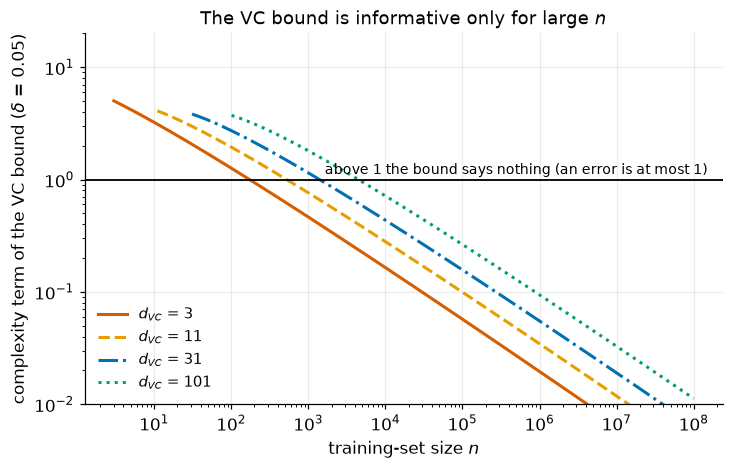

In [25]:
# Figure 3.8 — the complexity term of the VC bound
def figure_3_8():
    fig, ax = plt.subplots(figsize=(6.8, 4.4))
    styles = {3: (VERMILION, "-"), 11: (ORANGE, "--"), 31: (BLUE, "-."), 101: (GREEN, ":")}
    for d_vc, (color, ls) in styles.items():
        ns = np.logspace(np.log10(d_vc), 8, 400)
        ax.plot(ns, vc_term(ns, d_vc), color=color, linestyle=ls, linewidth=2, label=f"$d_{{VC}}$ = {d_vc}")
    ax.axhline(1.0, color="black", linewidth=1.2)
    ax.text(1.5e8, 1.12, "above 1 the bound says nothing (an error is at most 1)", fontsize=9, ha="right")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_ylim(1e-2, 20)
    ax.set(xlabel="training-set size $n$", ylabel="complexity term of the VC bound ($\\delta$ = 0.05)",
           title="The VC bound is informative only for large $n$")
    ax.legend(frameon=False, fontsize=9.5, loc="lower left")
    fig.tight_layout()
    plt.show()


figure_3_8()

The message of the table and of Figure 3.8 is sobering and important. Even for a **line in the plane** ($d_{\mathrm{VC}} = 3$) the guarantee is below 0.5 only after about 800 examples; for a linear classifier on the 30 features of the Breast Cancer data ($d_{\mathrm{VC}} = 31$) it takes more than 7000 examples to get below 0.5, and more than 270,000 to get below 0.1. With the 455 training examples of a typical split, the term is 1.57: the "guarantee" is **vacuous** (it exceeds 1, and any error is at most 1). The VC bound is worst-case over all distributions and all algorithms, with generous constants, and for any real data set it is far from the truth, as Section 3.10 will measure. Its value is **qualitative**: it tells us what the generalization gap depends on ($d$ and $n$, through $\sqrt{d\ln n/n}$) and proves that the class of linear classifiers *can* generalize, whatever the dimension, when $n$ is large enough.

:::{admonition} Pitfall — parameters are not capacity
:class: warning
For linear classifiers the VC dimension equals the number of parameters, and this has led to the folk rule "capacity = number of parameters". It is **false in general**. The one-parameter family $f_\omega(x) = \mathbb{I}[\sin(\omega x) > 0]$ has an *infinite* VC dimension: for any $n$ one can choose $n$ points that it shatters (Exercise 3.8). Conversely, a model with millions of parameters can have a small effective capacity if its parameters are constrained, which is exactly the subject of the next section, and which is why neural networks with more parameters than training examples can still generalize (Chapter 15).
:::

## 3.8 Rademacher complexity and the role of the norm

The VC dimension of a linear classifier grows with the dimension $d$, so the bound of Theorem 3.4 is empty when $d \ge n$. Yet ridge regression, support vector machines and kernel methods work well with $d \gg n$ (text with hundreds of thousands of word features, images, or the *infinite-dimensional* features of Chapter 9). What controls their capacity is not the dimension but the **size of the weights**, as we will see. To state this precisely we need a measure of capacity that depends on the *norm* of the weights and on the data, not only on the number of parameters. It is the Rademacher complexity.

### 3.8.1 Definition: how well can the class fit random signs?

A **Rademacher variable** is a random sign, equal to $+1$ or $-1$ with probability $\tfrac12$ each. Let $\sigma_1, \dots, \sigma_n$ be independent Rademacher variables. For a class $\mathcal{F}$ of real-valued functions and a sample $\mathbf{x}_1, \dots, \mathbf{x}_n$, the **empirical Rademacher complexity** is
$$
\hat{\mathfrak{R}}_S(\mathcal{F}) = \mathbb{E}_{\boldsymbol\sigma}\Big[\ \sup_{f \in \mathcal{F}}\ \frac1n\sum_{i=1}^n \sigma_i f(\mathbf{x}_i)\Big],
$$
and the **Rademacher complexity** $\mathfrak{R}_n(\mathcal{F})$ is its expectation over the random sample. Read the definition as an experiment: *assign random labels $\sigma_i \in \{\pm 1\}$ to the points, find the function of the class that correlates best with them, and average the best correlation over the random labels.* A class that can correlate well with pure noise is rich (it can fit noise, as the lines did in Section 3.7.3); a class that cannot is poor. It is the same idea as the VC dimension, but it measures *how well* the class fits noise on this sample, not only whether it can fit it perfectly.

**Theorem 3.5 (generalization bound with Rademacher complexity).** Let $\mathcal{G}$ be a class of functions with values in $[0, 1]$ (think of $g(\mathbf{x}, y) = \ell(y, f(\mathbf{x}))$ for $f \in \mathcal{H}$ and a bounded loss). For every $\delta \in (0, 1)$, with probability at least $1 - \delta$ over the draw of $n$ i.i.d. examples, **all** $g \in \mathcal{G}$ satisfy
$$
\mathbb{E}[g] \le \frac1n\sum_{i=1}^n g(\mathbf{z}_i) + 2\,\mathfrak{R}_n(\mathcal{G}) + \sqrt{\frac{\ln(1/\delta)}{2n}} ,
$$
and the same holds with $\mathfrak{R}_n(\mathcal{G})$ replaced by the computable $\hat{\mathfrak{R}}_S(\mathcal{G})$, provided the last term is replaced by $3\sqrt{\ln(2/\delta)/(2n)}$. The proof combines a symmetrization step with McDiarmid's bounded-difference inequality, a relative of Hoeffding's (Bartlett and Mendelson, 2002; Mohri et al., 2018, Theorem 3.3). Compared with Theorem 3.1, the term $\sqrt{\ln\lvert\mathcal{H}\rvert/(2n)}$ has been replaced by twice the Rademacher complexity.

Two tools make the theorem usable. The first is the **contraction lemma** (Ledoux and Talagrand): if $\varphi: \mathbb{R} \to \mathbb{R}$ is $L$-Lipschitz, then $\hat{\mathfrak{R}}_S(\varphi \circ \mathcal{F}) \le L\,\hat{\mathfrak{R}}_S(\mathcal{F})$, so composing the functions with a Lipschitz loss does not increase the complexity by more than the Lipschitz constant. The second is a direct computation for the class that matters most.

### 3.8.2 Linear functions with a bounded norm

**Proposition 3.6.** Let $\mathcal{F}_B = \{\mathbf{x} \mapsto \mathbf{w}^\top\mathbf{x} : \lVert\mathbf{w}\rVert_2 \le B\}$ and let the sample satisfy $\lVert\mathbf{x}_i\rVert_2 \le R$ for all $i$. Then
$$
\hat{\mathfrak{R}}_S(\mathcal{F}_B) = \frac{B}{n}\,\mathbb{E}_{\boldsymbol\sigma}\Big\lVert\sum_{i=1}^n \sigma_i\mathbf{x}_i\Big\rVert_2 \ \le\ \frac{B}{n}\sqrt{\sum_{i=1}^n\lVert\mathbf{x}_i\rVert_2^2} \ \le\ \frac{B\,R}{\sqrt{n}} .
$$

*Proof.* For a fixed sign vector, $\sup_{\lVert\mathbf{w}\rVert\le B}\ \mathbf{w}^\top\big(\tfrac1n\sum_i\sigma_i\mathbf{x}_i\big)$ is the largest value of a dot product over a ball. By the Cauchy–Schwarz inequality it is at most $B\,\lVert\tfrac1n\sum_i\sigma_i\mathbf{x}_i\rVert_2$, and it is **equal** to it for $\mathbf{w} = B\mathbf{u}/\lVert\mathbf{u}\rVert$ with $\mathbf{u} = \sum_i\sigma_i\mathbf{x}_i$. This gives the first equality. Next, Jensen's inequality for the concave function $\sqrt{\cdot}$ gives $\mathbb{E}\lVert\mathbf{u}\rVert \le \sqrt{\mathbb{E}\lVert\mathbf{u}\rVert^2}$, and
$$
\mathbb{E}\lVert\mathbf{u}\rVert^2 = \sum_{i, j}\mathbb{E}[\sigma_i\sigma_j]\,\mathbf{x}_i^\top\mathbf{x}_j = \sum_{i}\lVert\mathbf{x}_i\rVert^2,
$$
because $\mathbb{E}[\sigma_i\sigma_j] = 0$ for $i \ne j$ and $1$ for $i = j$. Finally $\sum_i\lVert\mathbf{x}_i\rVert^2 \le nR^2$. $\square$

The result is remarkable. **The complexity of the linear class does not depend on the dimension $d$**: it depends on the radius $B$ of the weights, the radius $R$ of the data, and $n$, and it shrinks like $1/\sqrt{n}$. A linear model in a million dimensions with $\lVert\mathbf{w}\rVert \le B$ is exactly as hard to estimate as one in two dimensions, if the data have the same radius. (If we bound the $\ell_1$ norm instead, $\lVert\mathbf{w}\rVert_1 \le B$, the complexity depends on the dimension only through $\sqrt{\ln d}$; this is why sparse methods can handle many more features than examples, Chapter 10 and Exercise 3.9.)

### Worked example 3.5 — a Rademacher complexity by hand

Take two real points $x_1 = 1$, $x_2 = 2$ and the class $\mathcal{F}_B = \{x \mapsto wx : \lvert w\rvert \le B\}$. By the first equality of Proposition 3.6,
$$
\hat{\mathfrak{R}}_S(\mathcal{F}_B) = \frac{B}{2}\,\mathbb{E}\big\lvert\sigma_1 + 2\sigma_2\big\rvert .
$$
The four equally likely sign vectors give $\lvert\sigma_1 + 2\sigma_2\rvert = 3, 1, 1, 3$, with mean $2$. Hence $\hat{\mathfrak{R}}_S = \tfrac{B}{2}\cdot 2 = B$, while the bound of the proposition is $\tfrac{B}{2}\sqrt{1 + 4} \approx 1.118\,B$: close, but not equal, as Jensen's inequality predicts. The check by enumeration of the sign vectors:

In [26]:
signs = np.array(list(product([-1, 1], repeat=2)))          # the four sign vectors
x_pts = np.array([1.0, 2.0])
B_rad = 1.0
exact = B_rad / 2 * np.mean(np.abs(signs @ x_pts))
bound = B_rad / 2 * np.sqrt(np.sum(x_pts ** 2))
print(f"empirical Rademacher complexity (B=1): {exact:.4f} | bound of Proposition 3.6: {bound:.4f}")

empirical Rademacher complexity (B=1): 1.0000 | bound of Proposition 3.6: 1.1180


### 3.8.3 Measured on a real data set

Let us measure $\hat{\mathfrak{R}}_S(\mathcal{F}_1)$ for the 30 standardized features of the Breast Cancer data, for samples of increasing size drawn from the 569 patients, by Monte Carlo: for each sample we draw 2000 random sign vectors and average $\lVert\sum_i\sigma_i\mathbf{x}_i\rVert_2/n$, which is the exact value by Proposition 3.6. We compare it with the two bounds of the proposition: the sharper one that uses the actual norms of the sample points, $\sqrt{\sum_i\lVert\mathbf{x}_i\rVert^2}/n$, and the cruder one that uses only the largest norm $R$.

In [27]:
from sklearn.preprocessing import StandardScaler

X_std = StandardScaler().fit_transform(X_bc)                         # the 569 x 30 Breast Cancer matrix, standardized
R_max = np.linalg.norm(X_std, axis=1).max()
print(f"largest norm of a data point: R = {R_max:.2f} (the typical norm is about {np.sqrt(30):.2f})")

rng = np.random.default_rng(SEED)
rows = []
for n in [25, 50, 100, 200, 400, 569]:
    Xs = X_std[rng.choice(N_BC, size=n, replace=False)]
    sigma = rng.choice([-1.0, 1.0], size=(2000, n))
    rademacher_mc = np.linalg.norm(sigma @ Xs, axis=1).mean() / n   # B = 1
    rows.append({"n": n, "Rademacher complexity (Monte Carlo)": rademacher_mc,
                 "bound with the actual norms": np.sqrt((Xs ** 2).sum()) / n, "bound R/sqrt(n)": R_max / np.sqrt(n)})
rademacher_table = pd.DataFrame(rows)
print(rademacher_table.round(4).to_string(index=False))

largest norm of a data point: R = 20.55 (the typical norm is about 5.48)
  n  Rademacher complexity (Monte Carlo)  bound with the actual norms  bound R/sqrt(n)
 25                               0.9295                       0.9603           4.1091
 50                               0.8383                       0.8810           2.9056
100                               0.5101                       0.5409           2.0546
200                               0.3621                       0.3771           1.4528
400                               0.2569                       0.2711           1.0273
569                               0.2147                       0.2296           0.8613


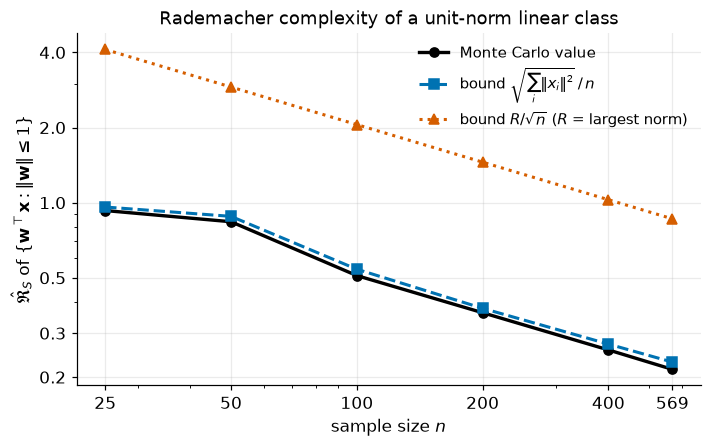

In [28]:
# Figure 3.9 — Rademacher complexity of unit-norm linear functions, Monte Carlo and bounds
def figure_3_9():
    from matplotlib.ticker import NullFormatter, ScalarFormatter

    r = rademacher_table
    fig, ax = plt.subplots(figsize=(6.6, 4.2))
    ax.plot(r["n"], r["Rademacher complexity (Monte Carlo)"], color="black", marker="o", linewidth=2.2, label="Monte Carlo value")
    ax.plot(r["n"], r["bound with the actual norms"], color=BLUE, marker="s", linestyle="--", linewidth=2, label=r"bound $\sqrt{\sum_i\|x_i\|^2}\,/\,n$")
    ax.plot(r["n"], r["bound R/sqrt(n)"], color=VERMILION, marker="^", linestyle=":", linewidth=2, label=r"bound $R/\sqrt{n}$ ($R$ = largest norm)")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set(xlabel="sample size $n$", ylabel=r"$\hat{\mathfrak{R}}_S$ of $\{\mathbf{w}^\top\mathbf{x}: \|\mathbf{w}\|\leq 1\}$",
           title="Rademacher complexity of a unit-norm linear class")
    ax.set_xticks(list(r["n"]))
    ax.set_yticks([0.2, 0.3, 0.5, 1, 2, 4])
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_formatter(ScalarFormatter())
        axis.set_minor_formatter(NullFormatter())
    ax.legend(frameon=False, fontsize=9.5)
    fig.tight_layout()
    plt.show()


figure_3_9()

The Monte Carlo value is **3% to 7% below the first bound**, so Jensen's inequality costs very little here, and it follows the $1/\sqrt{n}$ slope. The cruder bound $R/\sqrt{n}$ is about four times larger than the truth: it uses the largest norm in the data (20.5, an outlier among patients), while the typical norm is about 5.5. This is a useful lesson: the *data-dependent* version of a bound, which uses the actual sample, is much tighter than the version that uses worst-case quantities.

### 3.8.4 Margins: why large-margin classifiers generalize

For classification we want the 0–1 loss, which is not Lipschitz, so the contraction lemma does not apply to it directly. The trick is to bound it by a Lipschitz function of the **margin** $y\,f(\mathbf{x})$ of a prediction (positive when the prediction is correct, and large when it is confidently correct; labels are $y \in \{-1, +1\}$ here). Fix a margin level $\gamma > 0$ and define the **ramp loss** $\varphi_\gamma(z) = \min\{1, \max\{0, 1 - z/\gamma\}\}$: it equals 1 for $z \le 0$, decreases linearly to 0 at $z = \gamma$, and is $\tfrac1\gamma$-Lipschitz. It sits between the two quantities that we care about:
$$
\mathbb{I}[z \le 0] \ \le\ \varphi_\gamma(z) \ \le\ \mathbb{I}[z < \gamma].
$$
The left side says that the ramp loss bounds the 0–1 loss (the loss we want to control); the right side says that its empirical average is at most the **fraction of training points with margin below $\gamma$**. Applying Theorem 3.5 to the class $\{\varphi_\gamma(y f(\mathbf{x}))\}$ and the contraction lemma (the labels only flip the signs of the Rademacher variables, which does not change their distribution), we obtain:

**Theorem 3.7 (margin bound for norm-bounded linear classifiers).** Let $\lVert\mathbf{x}\rVert_2 \le R$ almost surely and $\gamma > 0$. With probability at least $1 - \delta$, **all** $\mathbf{w}$ with $\lVert\mathbf{w}\rVert_2 \le B$ satisfy
$$
\mathbb{P}\big(y\,\mathbf{w}^\top\mathbf{x} \le 0\big) \ \le\ \frac{1}{n}\,\#\big\{i : y_i\,\mathbf{w}^\top\mathbf{x}_i < \gamma\big\} + \frac{2BR}{\gamma\sqrt{n}} + \sqrt{\frac{\ln(1/\delta)}{2n}} .
$$

Read the three terms. The first is the fraction of training points that are misclassified or classified with a margin smaller than $\gamma$. The second is the capacity of the class and **depends on $BR/\gamma$, the radius of the weights times the radius of the data divided by the margin; it does not depend on $d$.** The third is the confidence term. If a classifier has *no* training points below margin $\gamma$ with a small $\lVert\mathbf{w}\rVert$, the bound is small; to get a small second term we want a **small norm for a given margin**. This is exactly what a **support vector machine** optimizes (Chapter 8: maximize the margin, equivalently minimize $\lVert\mathbf{w}\rVert$ with margin fixed at 1), and, in a softer way, what **ridge regression and weight decay** do (Chapter 6: penalize $\lVert\mathbf{w}\rVert^2$). The same bound is what makes kernel methods work in infinite dimensions (Chapter 9).

:::{admonition} Key idea
:class: tip
**Three ways of measuring the capacity of a class, one message.** For a finite class the capacity is $\ln\lvert\mathcal{H}\rvert$ (Section 3.6). For an infinite class it is the VC dimension, through $d\ln n$ (Section 3.7), or the Rademacher complexity, which measures how well the class fits random signs on the data (this section). In all three, the generalization gap shrinks like $\sqrt{\text{capacity}/n}$: **the training set must be large compared with the capacity of the model**. They differ in what capacity depends on: the *number* of functions, the *combinatorial richness* of the class, or, for Rademacher, the *norm* of the weights and the *geometry* of the data. Regularization, margins and early stopping do not change the number of parameters, but they shrink the effective class, and that is why they work.
:::

## 3.9 No free lunch: why learning needs assumptions

All the bounds of this chapter had the same structure: the generalization gap is controlled by a *capacity* of the class $\mathcal{H}$ that we **fixed in advance**. It is natural to ask whether there is a learning algorithm that needs no such restriction, a universal learner that is good on every problem. The answer is a clear no, and the proof is short enough to give in full.

**Theorem 3.8 (No Free Lunch, finite version).** Let the input domain be a finite set $\mathcal{X}$ with $N$ points, and suppose the labels are given by an arbitrary **target function** $t: \mathcal{X} \to \{0, 1\}$ (all $2^N$ functions are possible). A learning algorithm sees the labels $t(\mathbf{x})$ on $n < N$ training points and must predict the labels of the other $N - n$ points. Then, for **every** algorithm, the accuracy on the unseen points, **averaged over all $2^N$ targets**, is exactly $\tfrac12$.

*Proof.* Fix the training points. Group the $2^N$ targets according to the labels they give to these $n$ points: there are $2^n$ groups, each containing the $2^{N-n}$ targets that agree on the training points and take all possible values on the other $N - n$ points. All the targets of one group give the algorithm the same training data, so the algorithm makes the **same predictions** for all of them. Take an unseen point $\mathbf{x}$: in each group, exactly half of the targets give it the label 1 and half the label 0, so whatever the algorithm predicts for $\mathbf{x}$, it is right for exactly half of the group. Hence the average accuracy on every unseen point, and therefore on all of them, is $\tfrac12$. $\square$

Wolpert (1996) proved the general version for noisy targets and arbitrary loss functions, and Shalev-Shwartz and Ben-David give a probabilistic version (for any algorithm and any $n < \lvert\mathcal{X}\rvert/2$ there is a distribution on which the algorithm fails with constant probability). We can **watch the theorem at work** by enumerating all the $2^8 = 256$ Boolean functions of three bits, training four learners on four of the eight points and testing them on the other four.

In [29]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

points = np.array(list(product([0, 1], repeat=3)))                   # the 8 points of the domain {0,1}^3
train_idx, test_idx = np.array([0, 3, 5, 6]), np.array([1, 2, 4, 7])
all_targets = np.array(list(product([0, 1], repeat=8)))              # every possible labeling of the 8 points: 256 functions


def majority(X_tr, y_tr, X_te):
    return np.full(len(X_te), int(y_tr.mean() > 0.5))


def one_nn(X_tr, y_tr, X_te):
    return KNeighborsClassifier(n_neighbors=1).fit(X_tr, y_tr).predict(X_te) if len(set(y_tr)) > 1 else np.full(len(X_te), y_tr[0])


def stump(X_tr, y_tr, X_te):
    return DecisionTreeClassifier(max_depth=1, random_state=0).fit(X_tr, y_tr).predict(X_te)


def anti_stump(X_tr, y_tr, X_te):
    return 1 - stump(X_tr, y_tr, X_te)


def mean_accuracy(learner, targets):
    return np.mean([np.mean(learner(points[train_idx], t[train_idx], points[test_idx]) == t[test_idx]) for t in targets])


# A tiny "structured world": the six targets that copy one bit or its opposite
dictators = np.array([points[:, j] for j in range(3)] + [1 - points[:, j] for j in range(3)])
learners = {"majority vote": majority, "1-nearest neighbor": one_nn, "decision stump": stump, "anti-stump (opposite of the stump)": anti_stump}
nfl_table = pd.DataFrame({"all 256 targets": {k: mean_accuracy(f, all_targets) for k, f in learners.items()},
                          "6 'copy one bit' targets": {k: mean_accuracy(f, dictators) for k, f in learners.items()}})
nfl_table.round(4)

,all 256 targets,6 'copy one bit' targets
majority vote,0.5,0.5000
1-nearest neighbor,0.5,0.6667
decision stump,0.5,1.0000
anti-stump (opposite of the stump),0.5,0.0000


The first column is Theorem 3.8: **every learner, even the absurd "anti-stump", has an average accuracy of exactly 0.5** over the $256$ possible targets. Learning is impossible *on average over all worlds*. The second column shows what happens when the world is not arbitrary. If we know that the target simply copies one bit or its opposite, a stump (which can express exactly that) gets every unseen point right, 1-nearest neighbor does better than chance (0.67) and the anti-stump gets every one wrong. The learner that does well is not "better" in any absolute sense: its **assumptions fit the world**.

:::{admonition} Key idea
:class: tip
**Learning is possible only because we make assumptions** about how the world is: the **inductive bias** of a method. The theorem does *not* say that learning is impossible; it says that it is impossible *without assumptions*, and that every method embodies some. The real world is far from "all functions equally likely": nearby inputs tend to have similar labels, few features matter, relationships are smooth or compositional. Choosing a model family is choosing which of these assumptions to bet on. The rest of the book can be read as a catalog of inductive biases:

| Method | Assumption about the world | Chapter |
|---|---|---|
| $k$-nearest neighbors | similar inputs have similar labels | 4 |
| linear and logistic models | the label depends on a linear combination of the features | 6 |
| ridge, Lasso | the weights are small, or only a few are non-zero | 6, 10 |
| support vector machines, kernels | the classes are separated by a large margin in some feature space | 8, 9 |
| decision trees and ensembles | the label depends on a few features through simple threshold rules | 11 |
| convolutional networks | patterns are local and the same everywhere in the image | 16, 17 |
| recurrent networks, transformers | the order of the elements, and their dependencies, matter | 18, 19 |
:::

## 3.10 Theory meets practice

### 3.10.1 The generalization gap on a real data set

How do the bounds fare on real data? We train a logistic regression on the Breast Cancer data with training sets of increasing size, repeating each size 300 times with random splits, and measure the **generalization gap**: the test error minus the training error. The test set is whatever is left (569 minus $n$ patients), so it is large for small $n$. (The pipeline standardizes the features, as in Chapter 1; we use the default regularization, `C=1`.)

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(SEED)
rows = []
for n in [30, 60, 120, 240, 455]:
    train_err, test_err = [], []
    for _ in range(300):
        perm = rng.permutation(N_BC)
        tr, te = perm[:n], perm[n:]
        model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X_bc[tr], y_bc[tr])
        train_err.append(np.mean(model.predict(X_bc[tr]) != y_bc[tr]))
        test_err.append(np.mean(model.predict(X_bc[te]) != y_bc[te]))
    rows.append({"n": n, "training error": np.mean(train_err), "test error": np.mean(test_err)})
gap_table = pd.DataFrame(rows)
gap_table["mean gap"] = gap_table["test error"] - gap_table["training error"]
gap_table["VC term (d_VC = 31)"] = vc_term(gap_table["n"], 31)
slope = np.polyfit(np.log(gap_table["n"]), np.log(gap_table["mean gap"]), 1)[0]
print(gap_table.round(4).to_string(index=False))
print(f"\nslope of log(gap) against log(n): {slope:.2f}   (1/sqrt(n) would give -0.50)")

  n  training error  test error  mean gap  VC term (d_VC = 31)
 30          0.0026      0.0595    0.0570               3.8593
 60          0.0075      0.0437    0.0362               3.2112
120          0.0095      0.0333    0.0238               2.5668
240          0.0107      0.0278    0.0172               2.0026
455          0.0115      0.0228    0.0113               1.5697

slope of log(gap) against log(n): -0.58   (1/sqrt(n) would give -0.50)


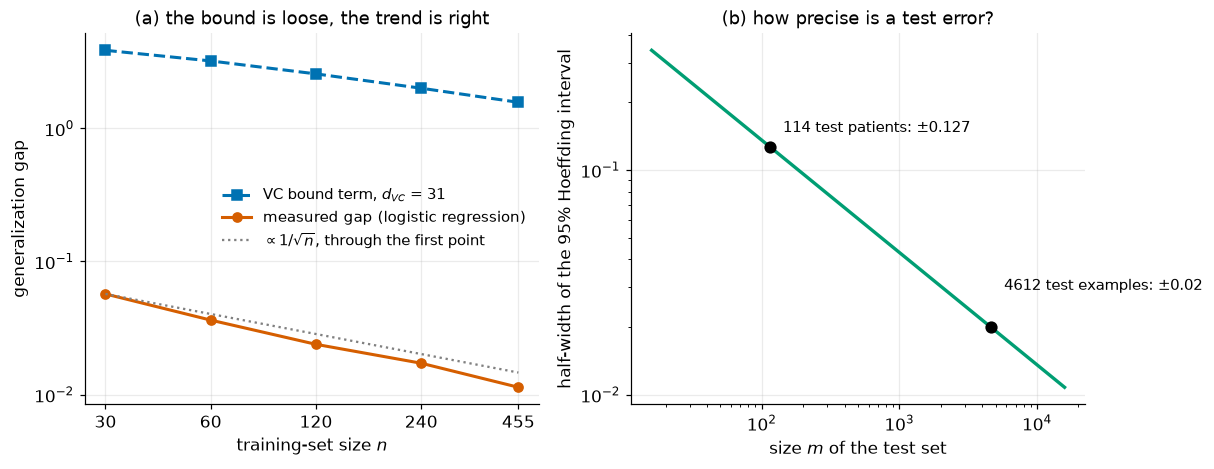

In [31]:
# Figure 3.10 — the gap on real data against the VC term, and the half-width of the test-set interval
def figure_3_10():
    g = gap_table
    fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.4))

    ax = axes[0]
    ax.plot(g["n"], g["VC term (d_VC = 31)"], color=BLUE, marker="s", linestyle="--", linewidth=2, label="VC bound term, $d_{VC}$ = 31")
    ax.plot(g["n"], g["mean gap"], color=VERMILION, marker="o", linewidth=2, label="measured gap (logistic regression)")
    ax.plot(g["n"], g["mean gap"].iloc[0] * np.sqrt(g["n"].iloc[0] / g["n"]), color="gray", linestyle=":", linewidth=1.5,
            label=r"$\propto 1/\sqrt{n}$, through the first point")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xticks(list(g["n"])); ax.set_xticklabels(list(g["n"])); ax.minorticks_off()
    ax.set(xlabel="training-set size $n$", ylabel="generalization gap", title="(a) the bound is loose, the trend is right")
    ax.legend(frameon=False, fontsize=9.5, loc="center right")

    ax = axes[1]
    m = np.logspace(1.2, 4.2, 200)
    ax.plot(m, np.sqrt(np.log(2 / 0.05) / (2 * m)), color=GREEN, linewidth=2.2)
    for m_mark, label, dy in [(114, "114 test patients: $\\pm$0.127", 1.15), (4612, "4612 test examples: $\\pm$0.02", 1.45)]:
        eps_mark = np.sqrt(np.log(2 / 0.05) / (2 * m_mark))
        ax.plot(m_mark, eps_mark, marker="o", color="black", markersize=7)
        ax.annotate(label, (m_mark, eps_mark), xytext=(m_mark * 1.25, eps_mark * dy), fontsize=9.5)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set(xlabel="size $m$ of the test set", ylabel="half-width of the 95% Hoeffding interval",
           title="(b) how precise is a test error?")
    fig.tight_layout()
    plt.show()


figure_3_10()

The gap of the logistic regression falls from 5.7 percentage points at $n = 30$ to 1.1 at $n = 455$: a decrease with a log-log slope of $-0.58$, close to the $-\tfrac12$ of $1/\sqrt{n}$ (the dotted line). The VC term, in contrast, is **between 1.6 and 3.9** over the same range: it is *vacuous* and **70 to 140 times larger than the real gap**. Both facts are what Section 3.7 predicted: the bound is worst-case over all distributions and all algorithms, and ours is neither; but it correctly says that the gap shrinks as the sample grows and that the speed is of the order of $1/\sqrt{n}$ (with a logarithmic factor). *Use the theory for the shape (what matters and how it scales), not for the numbers.* The numbers come from experiments with held-out data, as in the next subsection.

### 3.10.2 The one bound you will use every day: sizing a test set

There is one situation in which Hoeffding's inequality applies **without a union bound and without loss**: the evaluation of *one* function on *fresh* data. If a function $f$ was chosen without looking at the test set $T$ of $m$ examples (which are i.i.d. from $\mathcal{D}$ and independent of the training set), then $f$ is "fixed in advance" with respect to $T$, and with probability at least $1 - \delta$
$$
\big\lvert \hat{R}_T(f) - R(f)\big\rvert \le \sqrt{\frac{\ln(2/\delta)}{2m}}.
$$
So a test set is the right tool, and the formula tells how big it must be. For an error rate known to within $\pm 0.02$ with 95% confidence, $m \ge \ln(40)/(2 \cdot 0.02^2) = 4611.1$, that is **4612 examples**; for $\pm 0.01$ it is four times as many. Panel (b) of Figure 3.10 shows the half-width as a function of $m$. A data set of 569 patients with a test set of 114 (20%) gives a half-width of 0.127: the guarantee for that test set is weak, which is a consequence of how little data a test set of 114 contains, not of the method.

In [32]:
# One 80/20 split of the Breast Cancer data; the model is chosen and fitted on the training part only
rng = np.random.default_rng(SEED)
perm = rng.permutation(N_BC)
tr, te = perm[:455], perm[455:]
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X_bc[tr], y_bc[tr])
m_test = len(te)
k_err = int(np.sum(model.predict(X_bc[te]) != y_bc[te]))
half = np.sqrt(np.log(2 / 0.05) / (2 * m_test))
wilson = stats.binomtest(k_err, m_test).proportion_ci(confidence_level=0.95, method="wilson")
exact_ci = stats.binomtest(k_err, m_test).proportion_ci(confidence_level=0.95, method="exact")
print(f"test set of {m_test} patients: {k_err} errors, test error {k_err / m_test:.3f}")
print(f"Hoeffding 95% interval for the true risk   : [{max(0, k_err / m_test - half):.3f}, {k_err / m_test + half:.3f}]  (half-width {half:.3f})")
print(f"Wilson 95% interval                        : [{wilson.low:.3f}, {wilson.high:.3f}]")
print(f"Clopper-Pearson (exact) 95% interval       : [{exact_ci.low:.3f}, {exact_ci.high:.3f}]")
for k_models in (1, 10, 100):
    print(f"best of {k_models:>3} models compared on this test set: half-width {np.sqrt(np.log(2 * k_models / 0.05) / (2 * m_test)):.3f}")

test set of 114 patients: 1 errors, test error 0.009
Hoeffding 95% interval for the true risk   : [0.000, 0.136]  (half-width 0.127)
Wilson 95% interval                        : [0.002, 0.048]
Clopper-Pearson (exact) 95% interval       : [0.000, 0.048]
best of   1 models compared on this test set: half-width 0.127
best of  10 models compared on this test set: half-width 0.162
best of 100 models compared on this test set: half-width 0.191


The test error of this split is 0.9% (one mistake in 114 patients). The Hoeffding interval is wide: it reaches 0.136, because its half-width $\pm 0.127$ does not depend on how small the error is. The other two intervals, which exploit the fact that the error rate is small (a Bernoulli variable with small $p$ has a small variance, which Hoeffding ignores), are **about three times narrower** (both end at 0.048). They are the intervals to report in practice; Exercise 3.10 compares their coverage. The last lines of the output show what happens if a test set is used to choose among $k$ models: the guarantee degrades only like $\ln k$ (that is the union bound of Section 3.6), but, more importantly, the winner's curse of Section 3.4 returns. This is why we need **three** sets in practice: a training set to fit, a validation set to choose, a test set to report once (Chapter 5).

### 3.10.3 What the theory does not explain

The theory of this chapter is a foundation, not the end of the story, and it is honest to say where it stops.

- **The bounds are loose** by one to two orders of magnitude on real problems, as we have just measured. Tighter ones exist for particular classes and distributions (PAC-Bayes bounds, stability-based bounds), and are an active area of research.
- **Modern deep networks** have far more parameters than training examples, their VC dimension is enormous, and they can fit random labels perfectly (Zhang et al., 2017); yet they generalize well on real data. The classical capacity measures of this chapter do not explain this, and the answer involves the *dynamics of the optimizer* and the structure of real data (Chapter 15).
- **The i.i.d. assumption** (Section 3.2.1) fails whenever the data are collected over time, or the application differs from the training population; handling **distribution shift** requires different tools.
- The chapter studied **how large the gap can be**. It did not say how to *find* a function with a small empirical risk (optimization, Chapter 7), nor how to choose among the models of different complexity (model selection, Chapter 5).

## 3.11 Summary

- **Setting.** Data are i.i.d. draws from an unknown distribution $\mathcal{D}$. The goal is a small **expected risk** $R(f) = \mathbb{E}[\ell(y, f(\mathbf{x}))]$; what we can compute is the **empirical risk** $\hat{R}_S(f)$. The **Bayes predictor** (the conditional mean for the squared loss, the most probable class for the 0–1 loss) has the smallest possible risk $R^\ast$, which is positive when the labels are noisy.
- **ERM and its error.** Empirical risk minimization over a class $\mathcal{H}$ has excess risk = **estimation error** (random, shrinks with $n$, grows with the richness of $\mathcal{H}$) + **approximation error** (a property of $\mathcal{H}$, independent of $n$). The best complexity grows with $n$; the training error always prefers the richer class and cannot choose it.
- **Optimism.** $\mathbb{E}[\hat{R}_S(\hat f_S)] \le R(f_{\mathcal{H}}) \le \mathbb{E}[R(\hat f_S)]$. Picking the best of many candidates inflates the apparent performance by about $\sqrt{\ln m/(2n)}$.
- **Concentration.** Markov $\to$ Chebyshev (polynomial decay) $\to$ Chernoff $\to$ **Hoeffding**: for $n$ i.i.d. variables in $[0, 1]$, $\mathbb{P}(\lvert\bar X_n - \mu\rvert \ge \varepsilon) \le 2e^{-2n\varepsilon^2}$. A fixed function has $\lvert\hat{R}_S - R\rvert \le \sqrt{\ln(2/\delta)/(2n)}$ with probability $1 - \delta$.
- **Finite classes.** The union bound gives $\lvert R - \hat{R}_S\rvert \le \sqrt{(\ln\lvert\mathcal{H}\rvert + \ln(2/\delta))/(2n)}$ for all $f \in \mathcal{H}$ at once, so the estimation error of ERM is at most twice that. The class enters only through $\ln\lvert\mathcal{H}\rvert$.
- **Infinite classes.** The **VC dimension** is the size of the largest shattered set ($d + 1$ for linear classifiers in $\mathbb{R}^d$; Cover's counting formula). By Sauer–Shelah the growth function is polynomial after $d_{\mathrm{VC}}$, and the gap is at most $\sqrt{(8/n)(d\ln(2en/d) + \ln(4/\delta))}$. Parameters are not capacity ($\sin(\omega x)$ has one parameter and infinite VC dimension). A linear classifier fits random labels once $d \gtrsim n/2$.
- **Rademacher complexity** measures how well a class fits random signs on the data. For $\lVert\mathbf{w}\rVert_2 \le B$ and $\lVert\mathbf{x}\rVert_2 \le R$ it is at most $BR/\sqrt{n}$, **independent of the dimension**. The margin bound has the capacity term $2BR/(\gamma\sqrt{n})$: **small norm and large margin** control generalization, which is the reason for regularization, SVMs and kernels.
- **No Free Lunch.** Averaged over all possible targets every learner has accuracy $\tfrac12$ on unseen data. Learning needs **inductive biases**, and choosing a model family is choosing one.
- **In practice.** The bounds are loose by 1 to 2 orders of magnitude, but they predict the *shape* ($1/\sqrt{n}$, $\sqrt{\text{capacity}}$). The practical bound is Hoeffding's for a **test set**: $\pm\sqrt{\ln(2/\delta)/(2m)}$, so 4612 test examples for $\pm 0.02$ at 95% confidence.

### Data sources

- *Breast Cancer Wisconsin (Diagnostic)*: W. N. Street, W. H. Wolberg and O. L. Mangasarian, "Nuclear feature extraction for breast tumor diagnosis", *IS&T/SPIE 1993 International Symposium on Electronic Imaging: Science and Technology*, volume 1905, 861–870 (1993). Bundled with scikit-learn. In Section 3.6.1 the 569 patients are used as the *population* of a bootstrap world, and in Sections 3.8 and 3.10 as an ordinary data set.
- *The simulated world* of Sections 3.2 to 3.4 (two Gaussian classes in the plane) and the coin-flip experiments of Sections 3.4, 3.5 and 3.7 are **simulations**: they are used because the theory needs a distribution that is known exactly.

### Further reading

- S. Shalev-Shwartz and S. Ben-David, *Understanding Machine Learning: From Theory to Algorithms*, Cambridge University Press, 2014. The closest book to this chapter, with all the proofs we omitted (Sauer–Shelah, VC, Rademacher, No Free Lunch).
- M. Mohri, A. Rostamizadeh and A. Talwalkar, *Foundations of Machine Learning*, 2nd ed., MIT Press, 2018. Rademacher complexity and margin bounds in full detail (Chapters 3 and 5).
- Y. S. Abu-Mostafa, M. Magdon-Ismail and H.-T. Lin, *Learning From Data*, AMLBook, 2012. A very readable account of the VC dimension and of the form of the bound of Theorem 3.4.
- T. Hastie, R. Tibshirani and J. Friedman, *The Elements of Statistical Learning*, 2nd ed., Springer, 2009. Chapter 7 (model assessment and selection), with the statistician's view of optimism and of the bias–variance trade-off.
- V. N. Vapnik, *Statistical Learning Theory*, Wiley, 1998; V. N. Vapnik and A. Ya. Chervonenkis, "On the uniform convergence of relative frequencies of events to their probabilities", *Theory of Probability and Its Applications* 16(2), 264–280 (1971). The original sources of the VC theory.
- S. Boucheron, G. Lugosi and P. Massart, *Concentration Inequalities: A Nonasymptotic Theory of Independence*, Oxford University Press, 2013. For Hoeffding, Bernstein and the rest of the family.
- W. Hoeffding, "Probability inequalities for sums of bounded random variables", *Journal of the American Statistical Association* 58(301), 13–30 (1963).
- T. M. Cover, "Geometrical and statistical properties of systems of linear inequalities with applications in pattern recognition", *IEEE Transactions on Electronic Computers* EC-14(3), 326–334 (1965).
- P. L. Bartlett and S. Mendelson, "Rademacher and Gaussian complexities: risk bounds and structural results", *Journal of Machine Learning Research* 3, 463–482 (2002).
- L. G. Valiant, "A theory of the learnable", *Communications of the ACM* 27(11), 1134–1142 (1984). The paper that started the PAC (probably approximately correct) framework.
- D. H. Wolpert, "The lack of a priori distinctions between learning algorithms", *Neural Computation* 8(7), 1341–1390 (1996).
- C. Zhang, S. Bengio, M. Hardt, B. Recht and O. Vinyals, "Understanding deep learning requires rethinking generalization", *International Conference on Learning Representations* (2017).

## 3.12 Exercises

Difficulty: ★ warm-up, ★★ core, ★★★ challenge. Try each exercise before reading the hint; solutions and detailed outlines are in [Appendix C](../appendices/appendix_c_solutions.ipynb).

### Manual (analytical) exercises

**Exercise 3.1 ★ — The Bayes classifier with unequal priors.** A one-dimensional input $x$ satisfies $x \mid y = 0 \sim \mathcal{N}(0, 1)$ and $x \mid y = 1 \sim \mathcal{N}(2, 1)$, and only 20% of the examples belong to class 1: $\mathbb{P}(y = 1) = 0.2$. (a) Derive the Bayes classifier. Is its threshold the midpoint $x = 1$ of the two means? (b) Compute its risk $R^\ast$ in terms of $\Phi$. (c) Compute the risk of the classifier "always predict 0" and of the midpoint rule $\mathbb{I}[x > 1]$, and compare them with $R^\ast$.

*Hint.* Predict class 1 when $\pi_1 p_1(x) > \pi_0 p_0(x)$ and take logarithms. The error is $\pi_0\,\mathbb{P}(\text{predict } 1 \mid y = 0) + \pi_1\,\mathbb{P}(\text{predict } 0 \mid y = 1)$, and each probability is a value of $\Phi$.

**Exercise 3.2 ★ — Which prediction does each loss prefer?** (a) Prove that for the squared loss $\mathbb{E}\big[(y - f(\mathbf{x}))^2\big] = \mathbb{E}\big[(y - \eta(\mathbf{x}))^2\big] + \mathbb{E}\big[(\eta(\mathbf{x}) - f(\mathbf{x}))^2\big]$, with $\eta(\mathbf{x}) = \mathbb{E}[y \mid \mathbf{x}]$. (b) Let $y$ be uniform on $\{0, 1, 10\}$ with no input. Which constant $a$ minimizes $\mathbb{E}[(y - a)^2]$, and which minimizes $\mathbb{E}\lvert y - a\rvert$? Compute the two expected losses for each of the two constants, and comment on the role of the outlier.

*Hint.* For (a), add and subtract $\eta(\mathbf{x})$ and show that the cross term vanishes by conditioning on $\mathbf{x}$. For (b) the minimizer of the squared loss is the mean; for the absolute loss try the three data values as candidates (the expected absolute loss is piecewise linear in $a$).

**Exercise 3.3 ★★ — Sizing a test set.** You want to estimate the error rate of a classifier on fresh data to within $\pm 0.03$ with 95% confidence. (a) How many test examples does Hoeffding's inequality require? (b) How many does Chebyshev's inequality require in the worst case? (c) If you know that the true error rate is around $0.05$, Chebyshev with the actual variance $p(1 - p)$ asks for *fewer* examples than Hoeffding. Compute the number and explain why a bound that is worse in general can win here. (d) With only 1000 test examples, what is the half-width of the Hoeffding interval?

*Hint.* Hoeffding: $n \ge \ln(2/\delta)/(2\varepsilon^2)$. Chebyshev: $n \ge \sigma^2/(\varepsilon^2\delta)$, with $\sigma^2 \le \tfrac14$ for a Bernoulli variable.

**Exercise 3.4 ★★ — The realizable case.** Let $\mathcal{H}$ be a finite class and suppose that the target is *in* $\mathcal{H}$, so that some function has zero true risk and ERM can find a function $\hat f$ with **zero training error**. (a) Show that $\mathbb{P}\big(R(\hat f) > \varepsilon\big) \le \lvert\mathcal{H}\rvert\,e^{-\varepsilon n}$. (b) Hence $n \ge \big(\ln\lvert\mathcal{H}\rvert + \ln(1/\delta)\big)/\varepsilon$ examples suffice. Apply it to the class of **conjunctions** of literals over 10 binary variables, where each variable appears positively, negated, or not at all ($\lvert\mathcal{H}\rvert = 3^{10}$), with $\varepsilon = 0.05$ and $\delta = 0.01$. (c) Compare with the sample size that Corollary 3.2 requires for an estimation error of 0.05 in the *agnostic* case, and explain the difference in the dependence on $\varepsilon$.

*Hint.* A function with $R(f) > \varepsilon$ is consistent with one random example with probability at most $1 - \varepsilon$, so with all $n$ i.i.d. examples with probability at most $(1 - \varepsilon)^n \le e^{-\varepsilon n}$. Then use the union bound over the functions with risk above $\varepsilon$.

**Exercise 3.5 ★★★ — Why $\sqrt{\ln m}$?** (a) Let $Z_1, \dots, Z_m$ be random variables (not necessarily independent) such that $\mathbb{E}[e^{sZ_j}] \le e^{s^2\sigma^2/2}$ for all $s > 0$ and all $j$ ("sub-Gaussian with variance proxy $\sigma^2$"). Prove that $\mathbb{E}\big[\max_j Z_j\big] \le \sigma\sqrt{2\ln m}$. (b) Let $\hat{R}_1, \dots, \hat{R}_m$ be the training errors of $m$ candidates whose losses on $n$ training points are i.i.d. in $[0, 1]$ with mean $\mu$. Use Hoeffding's lemma to show that $\mathbb{E}[\mu - \min_j \hat{R}_j] \le \sqrt{\ln m/(2n)}$: the thin curves of Figure 3.4.

*Hint.* For (a), apply Jensen's inequality to the convex function $z \mapsto e^{sz}$ to get $e^{s\,\mathbb{E}[\max_j Z_j]} \le \mathbb{E}[e^{s\max_j Z_j}] = \mathbb{E}[\max_j e^{sZ_j}] \le \sum_j \mathbb{E}[e^{sZ_j}]$, take logarithms, and choose $s$ to minimize the bound. For (b), take $Z_j = \mu - \hat{R}_j$, an average of $n$ centered variables, each in an interval of length $1/n$: by Hoeffding's lemma $\mathbb{E}[e^{sZ_j}] \le e^{s^2/(8n)}$, so $\sigma^2 = 1/(4n)$.

### Python (computational) exercises

**Exercise 3.6 ★ — A Bayes classifier in the plane.** Two equally likely classes in $\mathbb{R}^2$ have the same covariance matrix $\boldsymbol\Sigma = \begin{pmatrix} 1 & 0.5 \\ 0.5 & 1\end{pmatrix}$ and means $\boldsymbol\mu_0 = (0, 0)^\top$ and $\boldsymbol\mu_1 = (2, 1)^\top$. (a) With the formula for the log-ratio of two Gaussians with equal covariance, find the direction $\mathbf{w}$ and threshold of the Bayes classifier, which is linear. (b) Compute the Bayes risk $\Phi(-\Delta/2)$, where $\Delta^2 = (\boldsymbol\mu_1 - \boldsymbol\mu_0)^\top\boldsymbol\Sigma^{-1}(\boldsymbol\mu_1 - \boldsymbol\mu_0)$ is the squared Mahalanobis distance between the means. (c) Check it by Monte Carlo with $10^6$ points. (d) Compare with the classifier that **ignores $x_1$** and the one that ignores $x_2$: which feature alone is more useful, and what is the risk of each?

*Hint.* For equal covariances, predict class 1 when $\mathbf{w}^\top\mathbf{x} > \mathbf{w}^\top(\boldsymbol\mu_0 + \boldsymbol\mu_1)/2$, with $\mathbf{w} = \boldsymbol\Sigma^{-1}(\boldsymbol\mu_1 - \boldsymbol\mu_0)$ (use `np.linalg.solve`). The one-feature risks are $\Phi(-\lvert\mu_{1j} - \mu_{0j}\rvert/(2\sigma_j))$.

**Exercise 3.7 ★★ — Approximation and estimation in regression.** Let $x \sim \mathcal{U}[0, 1]$ and $y = \sin(2\pi x) + \varepsilon$ with $\varepsilon \sim \mathcal{N}(0, 0.3^2)$, so that the Bayes risk for the squared loss is $\sigma^2 = 0.09$. The hypothesis class $\mathcal{H}_m$ is the set of polynomials of degree at most $m$, fitted by least squares (`np.polyfit`). (a) For $m \in \{1, 3, 6\}$ estimate the risk of $f_{\mathcal{H}_m}$ (the best polynomial; fit it on $10^5$ points) and hence the **approximation error** $R(f_{\mathcal{H}_m}) - R^\ast$. (b) For $n \in \{30, 300\}$, estimate by repeating 300 times the **expected risk** of the fitted polynomial and hence its estimation error $\mathbb{E}[R(\hat f_S)] - R(f_{\mathcal{H}_m})$. Report also the *median* risk over the 300 repetitions. (c) Present both errors for the six combinations of $m$ and $n$ in a table and comment on the trade-off: which degree is best at $n = 30$, which at $n = 300$?

*Hint.* Estimate every risk on one large fresh sample (for instance $10^5$ points, with the noisy $y$): the risks then include the noise $\sigma^2 = 0.09$, and the approximation error is the risk of $f_{\mathcal{H}_m}$ minus 0.09 (it can come out slightly negative for $m = 6$, a Monte Carlo error of the order of $10^{-3}$).

**Exercise 3.8 ★★ — Growth functions and a one-parameter class of infinite capacity.** (a) By brute force, count the dichotomies of $n = 1, \dots, 8$ points on a line produced by (i) half-lines $\mathbb{I}[x > t]$ and (ii) the *complements of intervals* $\mathbb{I}[x < a \text{ or } x > b]$, and find a formula for each. What are their VC dimensions? (b) Show that the class $f_\omega(x) = \mathrm{sign}(\sin(\omega x))$, $\omega \in \mathbb{R}$, shatters the points $x_j = 10^{-j}$, $j = 1, \dots, m$: for labels $y_j \in \{-1, +1\}$ take $\omega = \pi\big(1 + \sum_{i=1}^{m} \tfrac{1 - y_i}{2}\,10^{i}\big)$, and verify it numerically for $m = 6$ and all $2^6$ labelings.

*Hint.* For (b), $\omega x_j = \pi\big(10^{-j} + \sum_i b_i 10^{i - j}\big)$ with $b_i = (1 - y_i)/2$. Terms with $i > j$ are even multiples of $\pi$ and can be ignored; the term $i = j$ contributes $\pi b_j$; the remaining terms add to less than $\pi/5$.

**Exercise 3.9 ★★★ — Does the dimension matter? Rademacher complexity of $\ell_2$ and $\ell_1$ balls.** Take 100 standardized patients of the Breast Cancer data (30 features) and append $d - 30$ columns of independent standard Gaussian noise, for $d \in \{30, 100, 300, 1000, 3000\}$. For each $d$ estimate by Monte Carlo (2000 sign vectors) the empirical Rademacher complexity of (i) the $\ell_2$ ball $\lVert\mathbf{w}\rVert_2 \le 1$, equal to $\mathbb{E}\lVert\sum_i\sigma_i\mathbf{x}_i\rVert_2/n$, and (ii) the $\ell_1$ ball $\lVert\mathbf{w}\rVert_1 \le 1$, equal to $\mathbb{E}\max_j\lvert\sum_i\sigma_i x_{ij}\rvert/n$. Compare (i) with $\sqrt{\sum_i \lVert\mathbf{x}_i\rVert^2}/n$ and (ii) with $\max_j\lVert\mathbf{x}_{\cdot j}\rVert_2\,\sqrt{2\ln(2d)}/n$ (the bound for the $\ell_1$ ball), and describe how each complexity grows with $d$.

*Hint.* The supremum of a linear function over the $\ell_1$ ball is attained at a vertex: $\sup_{\lVert\mathbf{w}\rVert_1\le 1}\mathbf{w}^\top\mathbf{u} = \lVert\mathbf{u}\rVert_\infty$ (the largest absolute coordinate). The $\ell_1$ bound follows from Exercise 3.5, since each $\sum_i\sigma_i x_{ij}$ is sub-Gaussian with variance proxy $\sum_i x_{ij}^2$.

**Exercise 3.10 ★★★ — Which confidence interval for a test error?** A classifier makes $K$ errors on $m$ independent test examples, with unknown true error rate $p$. Compare three 95% intervals for $p$: (i) **Hoeffding**: $\hat p \pm \sqrt{\ln(2/0.05)/(2m)}$; (ii) **Wald** (normal approximation): $\hat p \pm 1.96\sqrt{\hat p(1 - \hat p)/m}$; (iii) **Wilson** (`scipy.stats.binomtest(K, m).proportion_ci(method="wilson")`). For $p \in \{0.03, 0.2\}$ and $m \in \{20, 50, 200\}$, simulate 20,000 test sets and report, for each interval, the **coverage** (the fraction of simulations in which the interval contains $p$) and the mean width. Which interval would you report, and why?

*Hint.* Draw $K \sim \mathrm{Binomial}(m, p)$ directly. The Wald interval collapses to a single point when $K = 0$. To avoid 20,000 calls to `binomtest`, compute the Wilson interval with its closed form, $\dfrac{\hat p + z^2/2m \pm z\sqrt{\hat p(1 - \hat p)/m + z^2/4m^2}}{1 + z^2/m}$ with $z = 1.96$.

## What comes next

With this chapter Part I is complete: we know what a learning problem is (Chapter 1), the tools to work with data (Chapter 2), and why learning from a sample is possible and what it costs (Chapter 3). From **Chapter 4** on we study learning methods one at a time. We begin with the simplest one, **$k$-nearest neighbors**, which you already implemented in Chapter 2, and we use it to see the trade-off of Section 3.3 in its classical form for the squared loss: the **bias–variance decomposition**, and why the "right" $k$ depends on the amount of data. **Chapter 5** turns the lessons of Sections 3.4 and 3.10 into practice: validation sets, cross-validation, and the metrics (precision, recall, ROC curves) with which classifiers are compared. In **Chapter 6** the norm bounds of Section 3.8 will appear as **ridge regression and regularized logistic regression**, and Chapters 8 and 9 build on the margin bound of Theorem 3.7 to derive support vector machines and kernel methods.